# Deep learning -  kennismaken met neurale netwerken

## Doelstelling van de opdracht

Deep learning, een kernonderdeel van machine learning, is cruciaal voor het ontsluiten van inzichten uit grote datasets, met toepassingen variërend van gezondheidszorg tot autonome voertuigen. Centraal in deep learning staan neurale netwerken. Deze opdracht focust op het bouwen en begrijpen van feedforward neurale netwerken in Keras voor classificatiedoeleinden, met een nadruk op het verkennen van de impact van verschillende hyperparameters.

In [2]:
!pip install scikit-learn
!pip install scikit-image
!pip install pandas
!pip install seaborn
!pip install scikit-optimize
!pip install imbalanced-learn

You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.
     |████████████████████████████████| 12.4 MB 2.4 MB/s eta 0:00:01
     |████████████████████████████████| 509 kB 1.5 MB/s eta 0:00:01
     |████████████████████████████████| 348 kB 2.4 MB/s eta 0:00:01
You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.
     |████████████████████████████████| 294 kB 1.7 MB/s eta 0:00:01
You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.
     |████████████████████████████████| 107 kB 2.6 MB/s eta 0:00:01
     |████████████████████████████████| 806 kB 3.7 MB/s eta 0:00:01
You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.
     |████████████████████████████████| 258 kB 2.6 MB/s eta 0:00:01
You should consider upgrading via the '/usr/bin/

In [3]:
%matplotlib inline
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.datasets import make_blobs

import matplotlib.image as mpimg
from skimage.io import imread, imshow

# distributions
from scipy.stats import randint
from scipy.stats import uniform

# Import Keras libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Dense, Dropout,BatchNormalization
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras import backend as K
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing import image

# Libraries voor Early stopping, ModelCheckpoint en load_model
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

## Warm-up

Hieronder worden 1000 random samples gegenereerd (getrokken uit vier Gaussiaanse verdelingen). De data bestaat uit 2 features en elke sample behoort tot één van de vier klasses.
Gebruik deze data om een neuraal netwerk te trainen dat als classifier optreedt.
De volledige datapipeline van deze opdracht is hieronder beschikbaar. De bedoeling is om de invloed van de hyperparameters uit te testen en de conclusies neer te schrijven in dit document. De vragen kan je onder de voorbeeldcode terugvinden.

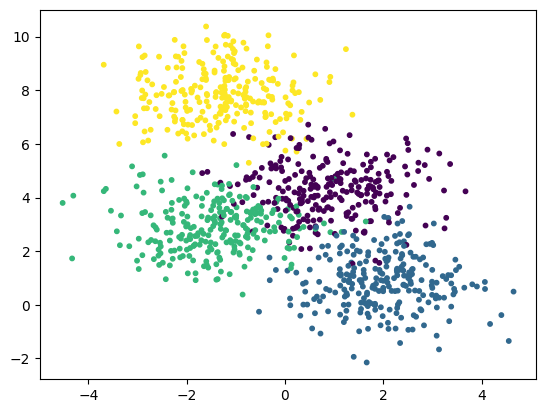

In [3]:
# Aanmaken van de dataset
X, y = make_blobs(n_samples=1000, centers=4, center_box=(-10, 10), random_state=0, cluster_std=1)
plt.scatter(X[:, 0], X[:, 1], s=10, c=y)
plt.show()

In [4]:
# splitsen in test set en training set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state =0)
y_test_orig = y_test
# ---------------------------------------------------
# normaliseren van de input data

scaler = StandardScaler()
scaler.fit(X_train)
X_scaled = scaler.transform(X)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

#----------------------------------------------------
# one-hot encoding op output
print (y_train[0])
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
print(y_train[0])

num_classes = y_train.shape[1]

1
[0. 1. 0. 0.]


In [5]:
# One-hot encoding van de klassenlabels
# encoder = LabelEncoder()
# encoded_y = encoder.fit_transform(y)
# categorical_y = to_categorical(encoded_y)
categorical_y = to_categorical(y)
categorical_y_train = to_categorical(y_train)
num_classes = categorical_y.shape[1]

In [6]:
print(y_test.shape)

print(y_train.shape)

(200, 4)
(800, 4)


In [7]:
X_train.shape

(800, 2)

# Warmup Deel 1: de code die werd gebruikt.  In deel 2 wordt per vraag een overzicht gegeven van de resultaten en de conclusies.

In [8]:
##################
##ACTIVATIE HIDDEN
##################
activation_hidden = 'relu' # activatiefunctie van de hidden layer neuronen
# activation_hidden = 'sigmoid'
# activation_hidden = 'tanh'

activation_output = 'sigmoid'# activatie van de output layer neuronen

# Initializers:
initializer = 'RandomUniform' # type van kernel intializer
# initializer = 'RandomNormal'
# initializer = 'TruncatedNormal'
# initializer = 'Zeros'
# initializer = 'Ones'
# initializer = 'GlorotNormal'
# initializer = 'GlorotUniform'
# initializer = 'Constant'

############
##OPTIMIZERS
############
SGD = tf.keras.optimizers.SGD(learning_rate=0.01) # Gradient Descent with momentum optimizer (default momentum = 0)

# RMSprop en optimizers die daarop zijn gebaseerd:
RMSprop = tf.keras.optimizers.RMSprop(learning_rate=0.01) # plain momentum / moving discounted avg of square of gradients
adam = tf.optimizers.Adam(learning_rate=0.01) # RMSprop met momentum; SGD methode
nadam = tf.keras.optimizers.Nadam(learning_rate=0.01) # adam met Nesterov momentum
adamax = tf.keras.optimizers.Adamax(learning_rate=0.01) # adam variant, based on the infinity norm, sometimes superior to adam

# niet RMSprop optimizers:
adagrad = tf.keras.optimizers.Adagrad(learning_rate=0.01) # parameter-specific learning rates, adapted relative to frequence: 
# the more updates a parameter receives, the smaller the updates.
adadelta = tf.keras.optimizers.Adadelta(learning_rate=0.01) # more robust implementation of adagrad 
# (learning rate adaptation based on moving window of gradient updates)

ftrl = tf.keras.optimizers.Ftrl(learning_rate=0.01) # L1 en L2 ondersteuning

In [9]:
# NN parameters
batch_size = 32
epochs = 100
dropoutrate = 0.0 # typisch tussen 10% en 50%: 20-30% bij RNN's, en 40-50% in CNN's
# In practice, you can usually apply dropout only to the neurons in the top one to three layers (excluding the output layer).

input_dim = X.shape[1]

In [10]:
y_train.shape

(800, 4)

In [11]:
# Het model
model = Sequential()
model.add(Dense(16, input_dim=input_dim, kernel_initializer=initializer,activation=activation_hidden))
model.add(Dropout(dropoutrate))

# output layer
model.add(Dense(num_classes, kernel_initializer=initializer,activation=activation_output))

model.compile(loss='categorical_crossentropy',optimizer='RMSprop',metrics=['accuracy'])

# train the model

history = model.fit(X_train, y_train, epochs=epochs, validation_split = 0.2,verbose=1)


Epoch 1/100
20/20 [==============================] - 2s 8ms/step - loss: 1.3749 - accuracy: 0.6469 - val_loss: 1.3622 - val_accuracy: 0.6438
Epoch 2/100
20/20 [==============================] - 0s 3ms/step - loss: 1.3474 - accuracy: 0.6719 - val_loss: 1.3308 - val_accuracy: 0.6000
Epoch 3/100
20/20 [==============================] - 0s 3ms/step - loss: 1.3112 - accuracy: 0.6406 - val_loss: 1.2908 - val_accuracy: 0.5750
Epoch 4/100
20/20 [==============================] - 0s 3ms/step - loss: 1.2673 - accuracy: 0.6313 - val_loss: 1.2450 - val_accuracy: 0.5500
Epoch 5/100
20/20 [==============================] - 0s 3ms/step - loss: 1.2176 - accuracy: 0.6141 - val_loss: 1.1943 - val_accuracy: 0.5500
Epoch 6/100
20/20 [==============================] - 0s 3ms/step - loss: 1.1646 - accuracy: 0.6172 - val_loss: 1.1420 - val_accuracy: 0.5500
Epoch 7/100
20/20 [==============================] - 0s 3ms/step - loss: 1.1099 - accuracy: 0.6234 - val_loss: 1.0884 - val_accuracy: 0.5500
Epoch 8/100
2

Epoch 59/100
20/20 [==============================] - 0s 2ms/step - loss: 0.1912 - accuracy: 0.9328 - val_loss: 0.2006 - val_accuracy: 0.9375
Epoch 60/100
20/20 [==============================] - 0s 2ms/step - loss: 0.1901 - accuracy: 0.9312 - val_loss: 0.1996 - val_accuracy: 0.9312
Epoch 61/100
20/20 [==============================] - 0s 3ms/step - loss: 0.1884 - accuracy: 0.9344 - val_loss: 0.1989 - val_accuracy: 0.9375
Epoch 62/100
20/20 [==============================] - 0s 3ms/step - loss: 0.1873 - accuracy: 0.9312 - val_loss: 0.1975 - val_accuracy: 0.9312
Epoch 63/100
20/20 [==============================] - 0s 3ms/step - loss: 0.1863 - accuracy: 0.9328 - val_loss: 0.1959 - val_accuracy: 0.9438
Epoch 64/100
20/20 [==============================] - 0s 3ms/step - loss: 0.1852 - accuracy: 0.9328 - val_loss: 0.1951 - val_accuracy: 0.9438
Epoch 65/100
20/20 [==============================] - 0s 3ms/step - loss: 0.1842 - accuracy: 0.9328 - val_loss: 0.1944 - val_accuracy: 0.9375
Epoch 

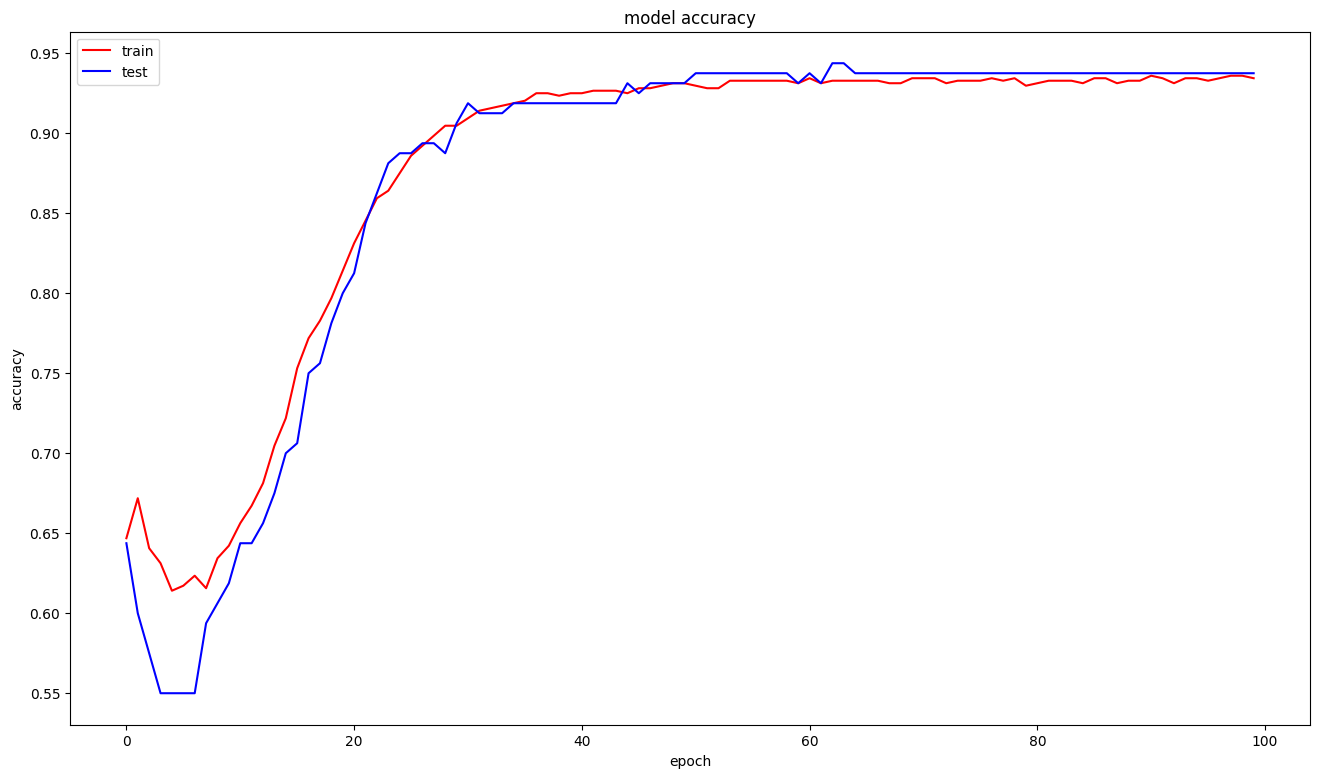

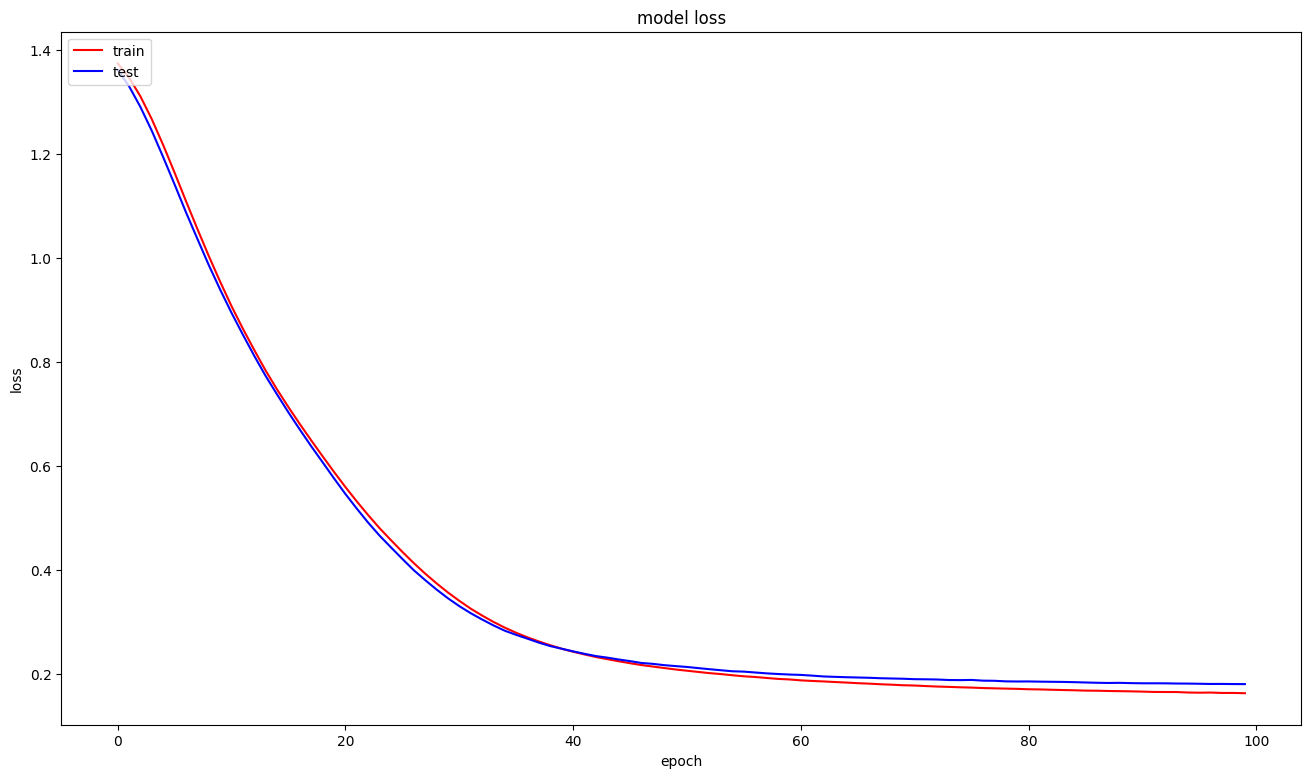

In [12]:
# Plot history

# Accuray 
fig = plt.figure(figsize=(16,9))
plt.plot(history.history['accuracy'],'r')
plt.plot(history.history['val_accuracy'],'b')
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()
# Loss 
fig = plt.figure(figsize=(16,9))
plt.plot(history.history['loss'],'r')
plt.plot(history.history['val_loss'],'b')

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

Aantal keren dat h in de range x1_max - x1_min (x) past:
364
Aantal keren dat h in de range x2_max - x2_min (y) past:
330
Shape van xx en yy: 
(330, 364) (330, 364)
3754/3754 [==============================] - 3s 804us/step


(-3.233002394275881, 3.346997605724124)

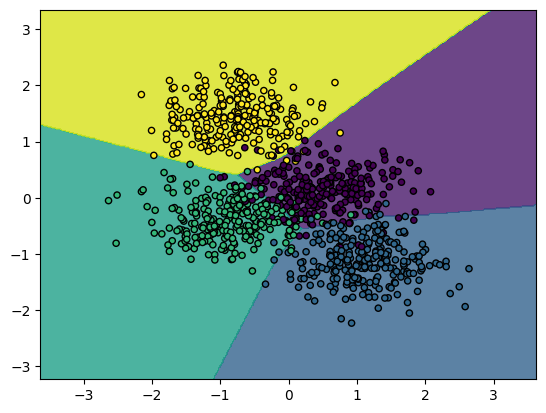

In [13]:
# Maak een rooster
h = .02  # Rooster stapgrootte
# grenzen van x en y assen bepalen; extra marge van 2 eenheden
x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1  # eerste element van elk datapunt (x)
y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1  # tweede element van elk datapunt (y)

print(f"Aantal keren dat h in de range x1_max - x1_min (x) past:")
print(round((x_max - x_min)/h))
print(f"Aantal keren dat h in de range x2_max - x2_min (y) past:")
print(round((y_max - y_min)/h))


# np.meshgrid: genereer een 2D rooster over het gespecifieerde bereik
# np.arange: genereer een reeks getallen tussen min en max met interval h
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

print("Shape van xx en yy: ")
print(xx.shape, yy.shape)


# xx bevat de x-coördinaten voor elk punt in het rooster.  Er zijn x coördinaten voor elke y value
# rij, dus 2D...

# Voorspellingen op het rooster
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])  
# np.c_[...]: Dit is een NumPy-functie die twee 1D-arrays samen 'column-wise' samenvoegt, 
# ofwel als kolommen naast elkaar in een 2D-array. Je kunt het zien als het 'plakken' van de 
# twee arrays aan elkaar om een matrix te maken waar elke rij een paar van overeenkomstige elementen bevat.
# Dit komt overeen met een vstack gevolgd door .T (transpose)
Z = np.argmax(Z, axis=1)
Z = Z.reshape(xx.shape)

# Plot de beslissingsgrens
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y, edgecolors='k', s=20)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())

7/7 [==============================] - 0s 958us/step

Classification report:
              precision    recall  f1-score   support

           0       0.80      0.80      0.80        44
           1       0.94      0.96      0.95        51
           2       0.86      0.88      0.87        48
           3       1.00      0.96      0.98        57

    accuracy                           0.91       200
   macro avg       0.90      0.90      0.90       200
weighted avg       0.91      0.91      0.91       200

90.5


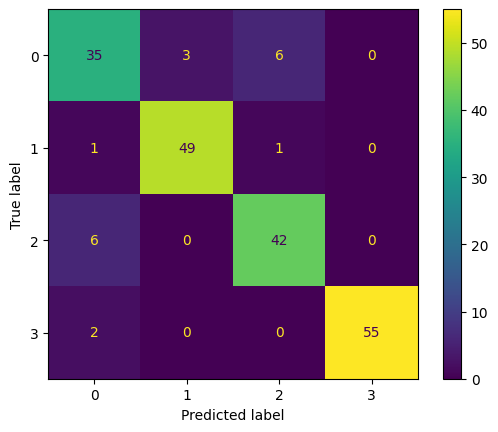

In [14]:
# Testen met test set
y_pred = model.predict(X_test)

y_pred = np.argmax(y_pred, axis=1)  


print('\nClassification report:')
print(classification_report(y_test_orig, y_pred))

cm = confusion_matrix(y_test_orig, y_pred, labels=[0,1,2,3])

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=[0,1,2,3])
disp.plot()
print(accuracy_score(y_test_orig, y_pred) * 100) 

# Opdrachten warm-up oefening - deel 2

1. Varieer bij SGD de learning rate en onderzoek wat er gebeurt wanneer deze te klein of te groot wordt. Wat is de invloed van normalisatie op de learning rate en de plot van de model loss?

De variatie van de learning rate bij SGD heeft een invloed op de resultaten, maar we komen nooit tot een degelijk resultaat.  De accuracy op de training set is bij kleine learning rates constanter, maar nooit goed; bij vergroten van de learning rate wordt de accuracy bovendien zeer grillig: het model leert niet echt bij
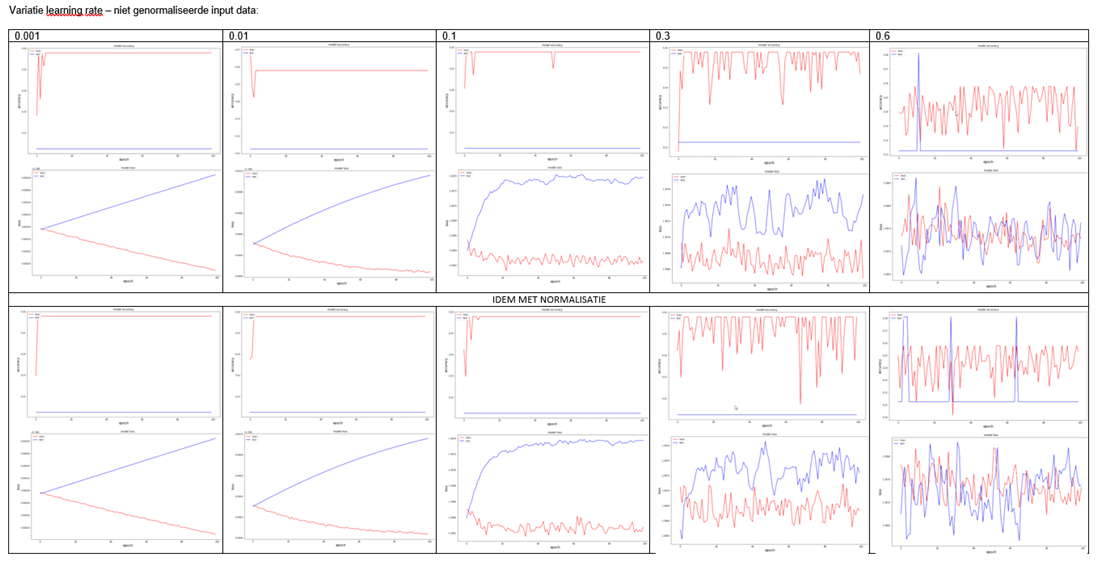

Invloed van de normalisatie:
Op deze dataset en gebruikmakend van SGD is er geen noemanswaardig effect op te merken door normalisatie van de data.


2. Probeer verschillende optimizers uit: SGD, Adam, RMSProp, Adagrad, ... (https://keras.io/optimizers/). Kijk wat er gebeurt in termen van de model loss curve en de accuracy.

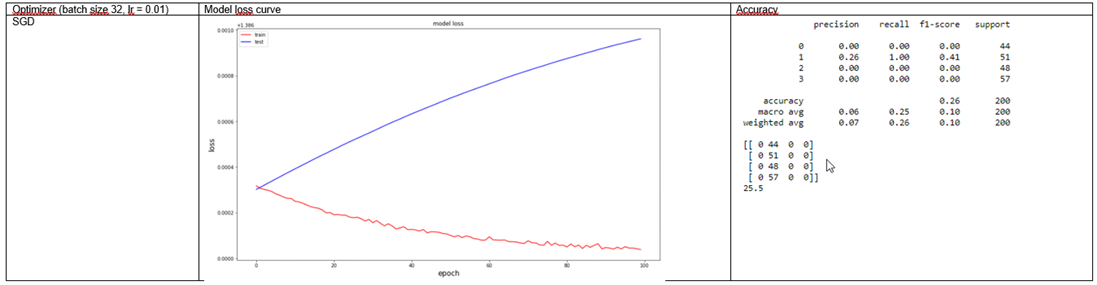
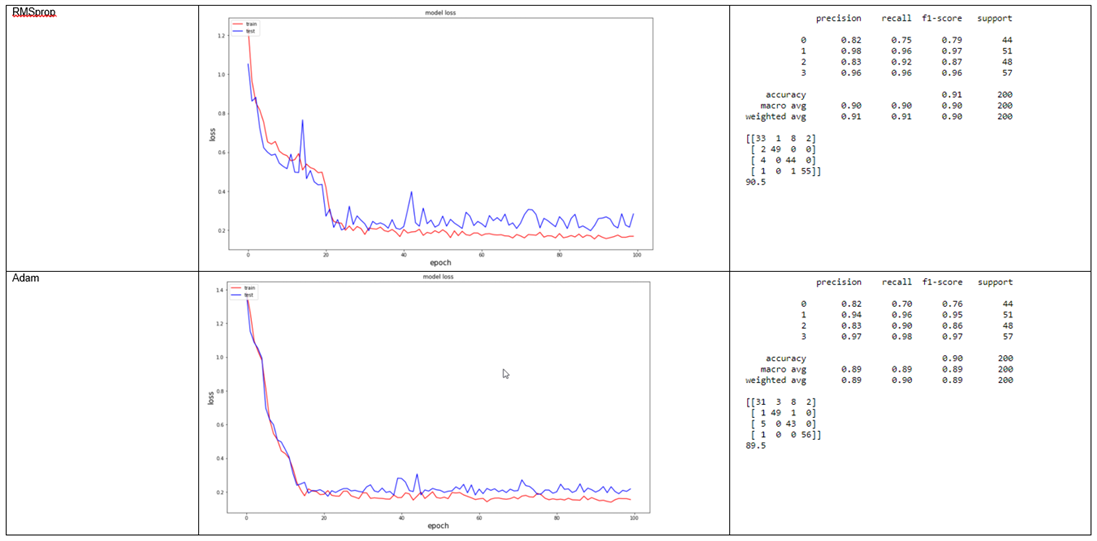
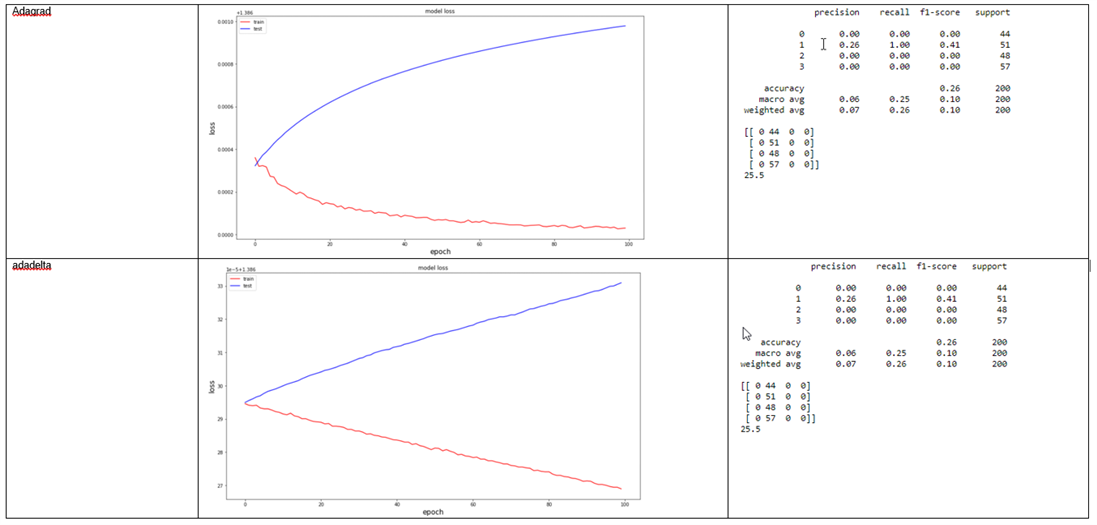
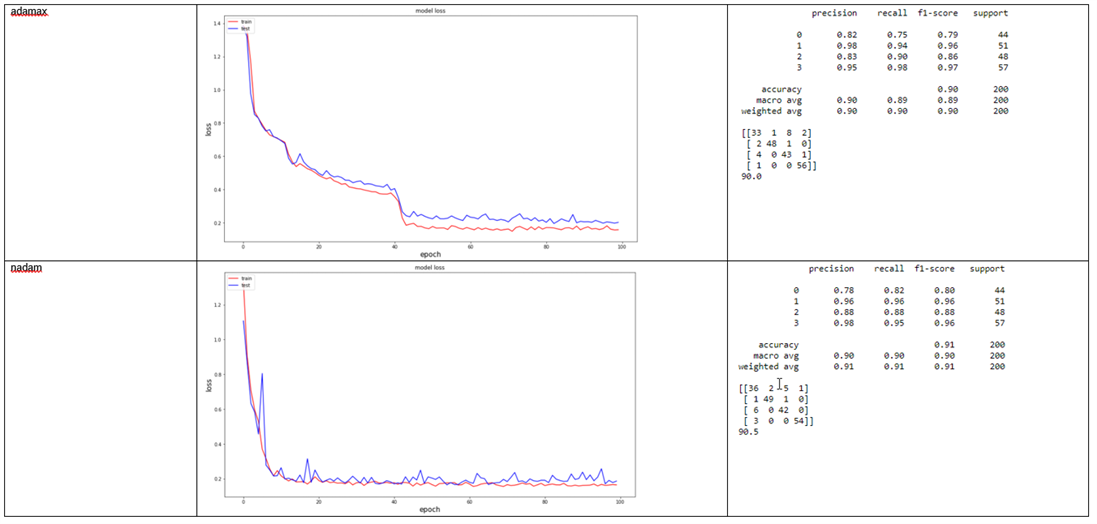
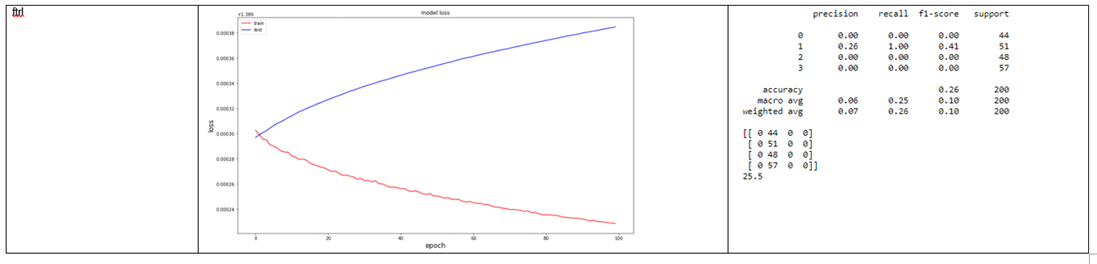

Conclusie: de groep optimizers die gebaseerd is op RMSprop (RMSprop, adam, nadam, adamax) werkt, de anderen niet.  De optimizers die werken halen een accuracy van rond de 90% en hebben een loss curve met een sterk dalende trend in het begin, en een min of meer stabiele trend bij meer epochs.  Nadam geeft op het eerste zicht de beste loss curve (train en test loss curve dichtst bijeen) en geeft ook de beste accuracy, zij het met maar een minimaal voordeel tov de andere optimizers.  De optimizer speelt dus wel degelijk een rol.  

3. Kies een dropoutrate van 0.8. Verklaar wat er gebeurt. Zet nadien de dropout rate terug naar 0.0
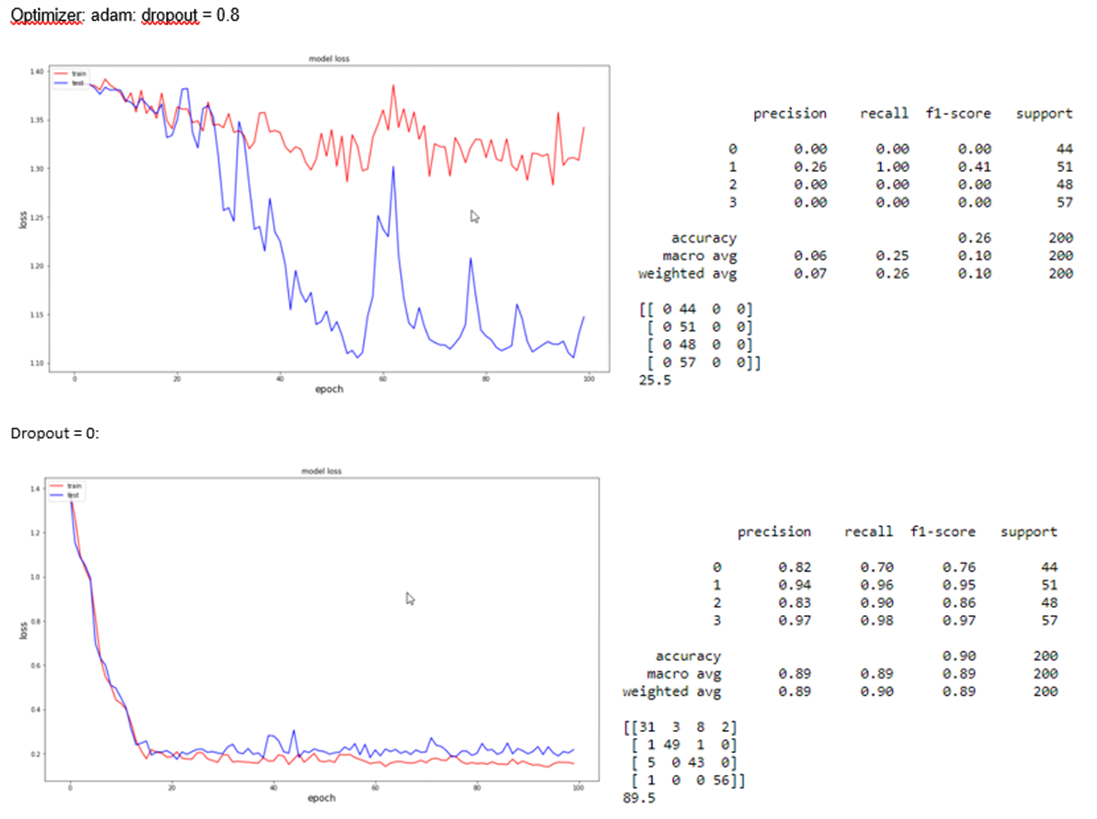

Conclusie:
Dropout is een techniek om overfitting te voorkomen.  Bij dropout = 0 zagen we dat de loss op de test set iets hoger was dan op de training set.  Dit betekent dat de prestaties op de trainingsset iets beter zijn, maar niet spectaculair veel.  Er is dus een lichte mate van overfitting.  Dropout kan worden toegepast, maar een dropout van 80% is veel te hoog waardoor we van licht overfitting naar sterk underfitting gaan: het model is veel te simpel en leert niet echt meer.

4. Verhoog het aantal neuronen in de hidden layers. Wat is de invloed daarvan?

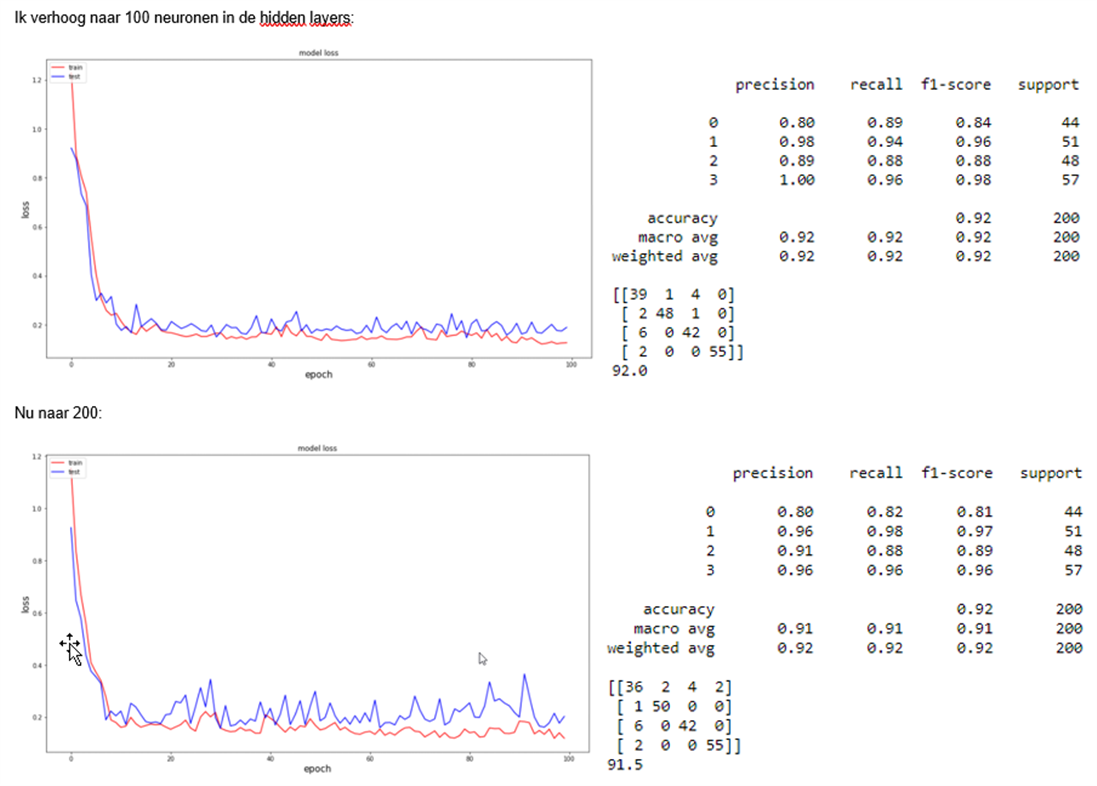

Conclusie: met meer (tot op een zekere grens!) neuronen wordt na een lager aantal epochs al een lagere loss bekomen.  Bij 100 neuronen is het eindresultaat ook beter: een accuracy van 92%, waar we met 20 neuronen “slechts” 89,5% hadden.  Verhogen van het aantal neuronen zorgt dus voor een beter model, alvast tot het model te complex wordt:

nog meer neuronen toevoegen voegt niks meer toe: met 200 neuronen wordt niet met nog minder epochs een lagere loss bekomen, en de accuracy gaat erop achteruit.  

Het model wordt dus te complex en er treedt overfitting op: de training set wordt "van buiten" geleerd en de loss op de test set gaat omhoog: het model begint slechter te presteren op de test set.

#### Een model moet dus voldoende neuronen hebben om de informatie uit de input data te "bewaren" (bij  te weinig neuronen gaat er informatie verloren), maar teveel neuronen toevoegen werkt dan weer overfitting in de hand.


5. Verhoog het aantal hidden layers. Wat merk je? Bekijk de decision boundary. Controleer of je met overfitting te maken hebt. Verhoog nu de dropout rate. Verklaar wat er gebeurt.
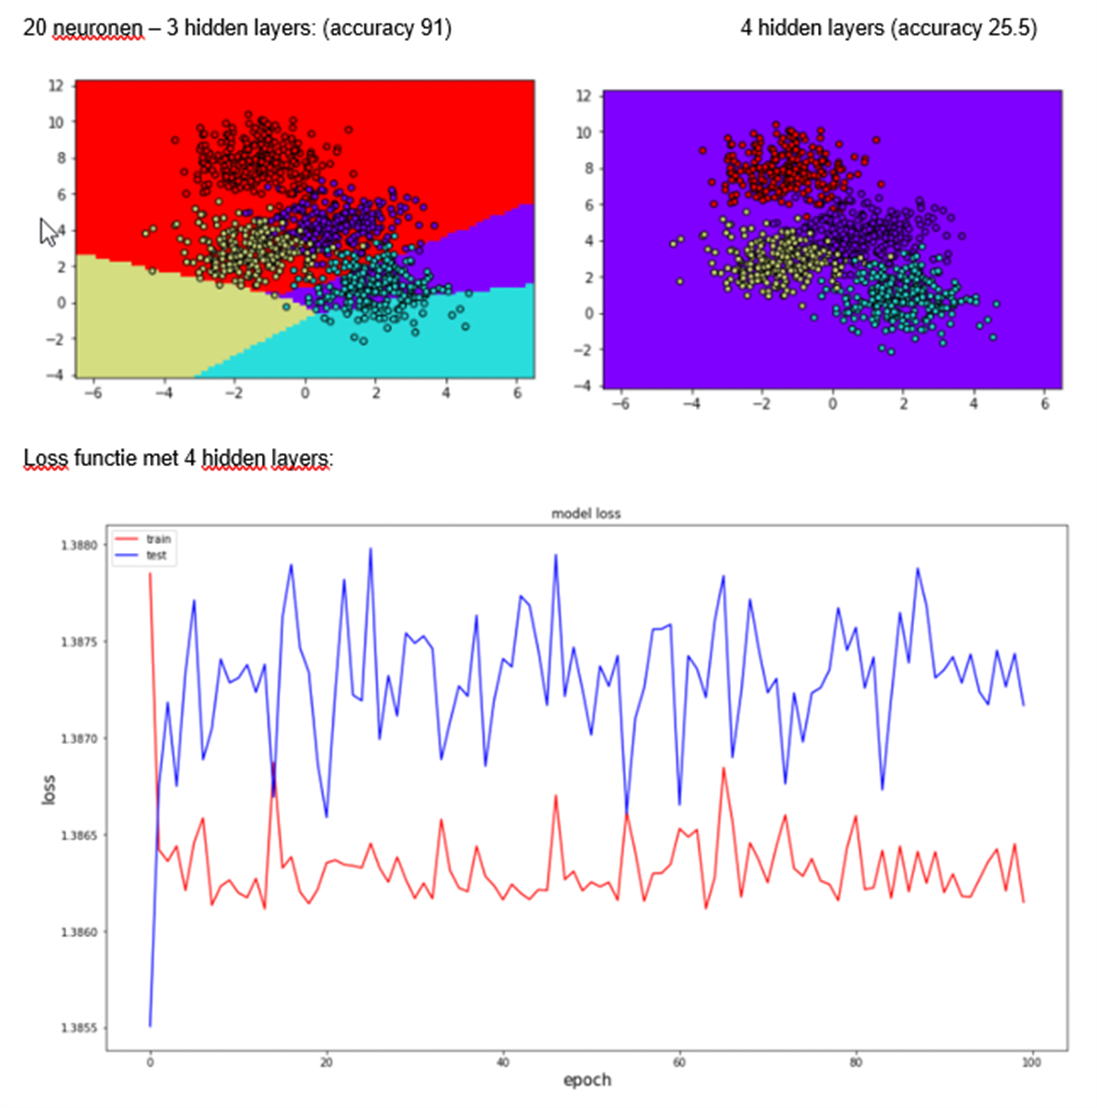

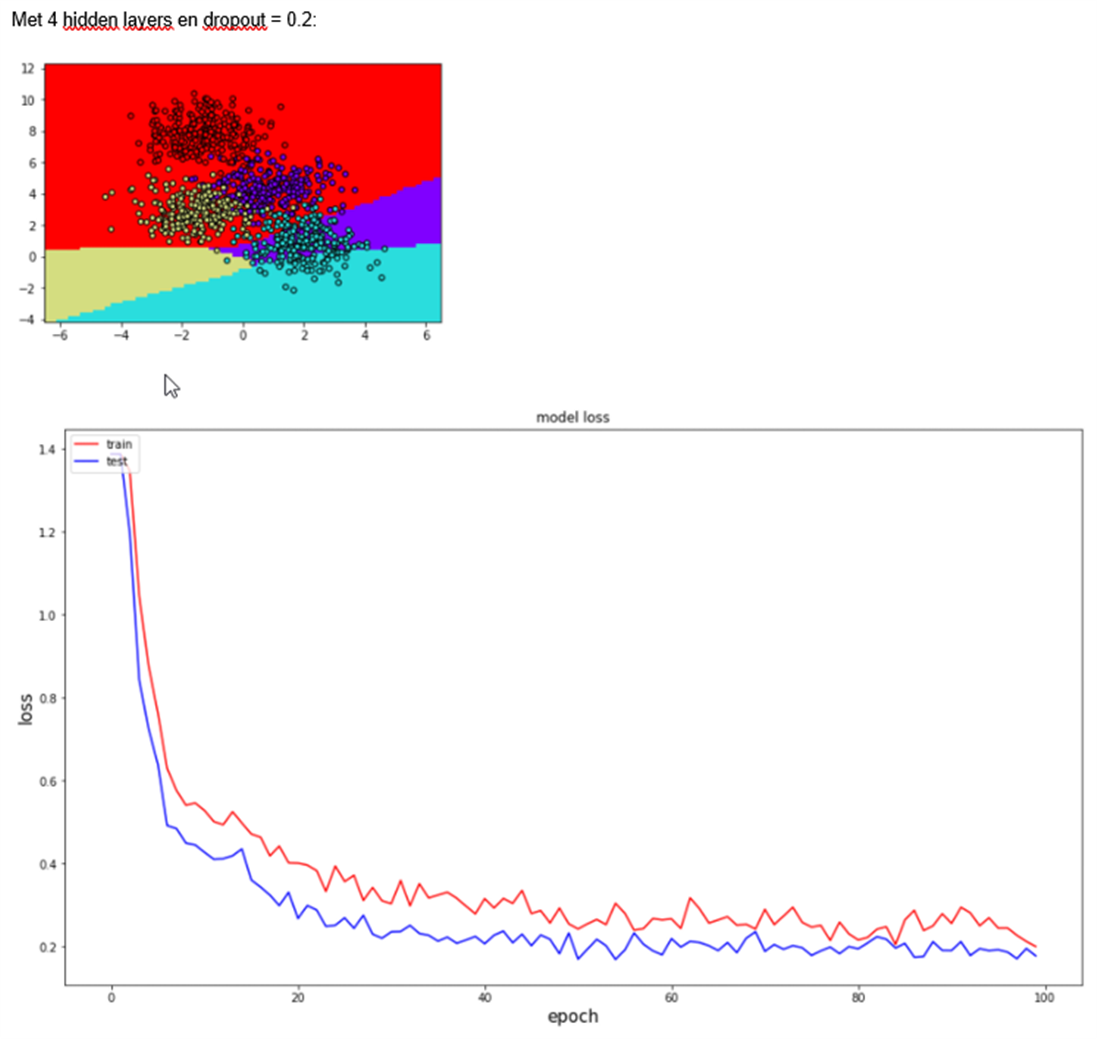

Conclusie: bij het toevoegen van een vierde hidden layer verliest het model zijn onderscheidend vermogen: het is veel te complex geworden, en modelleert niet meer.  Door dropout toe te passen regulariseren we het model en kan het opnieuw de klasses onderscheiden, met een resultaat zoals voorheen.  

Als er meer hidden layers worden toegevoegd, kan er met veel minder neuronen per laag worden gewerkt: "diepe" netwerken kunnen (complexe) functies modelleren met veel minder neuronen per laag, waardoor ze betere performantie halen met dezelfde hoeveelheid training data.

6. Bespreek de invloed van batchnormalization.

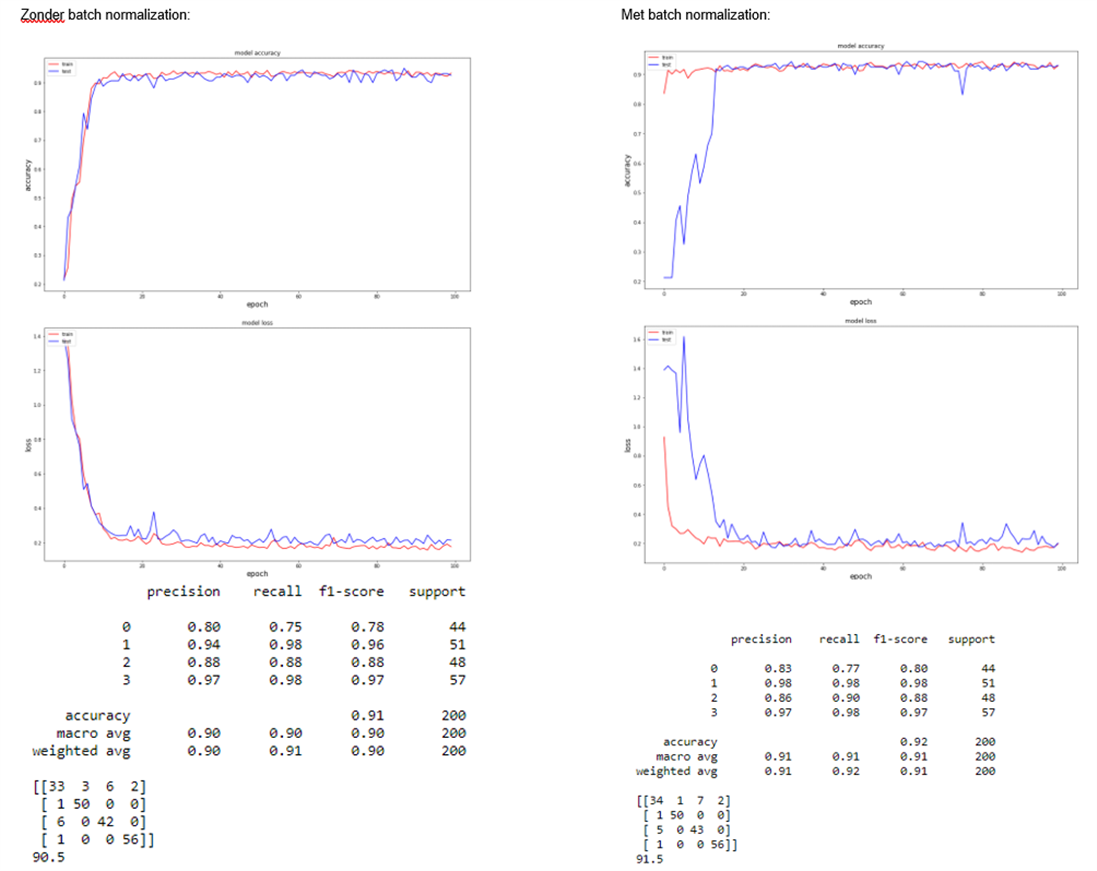

Met batch normalization liggen de loss en accuracy curves van de train en test set dichter bijeen dan zonder batch normalization.  Dit betekent dat de toepassing van batch regularization een regulariserend effect heeft, waardoor minder overfitting optreedt.  De accuracy is ook iets beter met toepassing van batch regularization.

Op de training set is het ook zo dat het model sneller leert.  De learning rate kan met gebruik van batch normalization hoger zijn dan zonder batch normalization.

7. Probeer verschillende activatiefuncties uit bij de hidden layers. (https://keras.io/activations/)

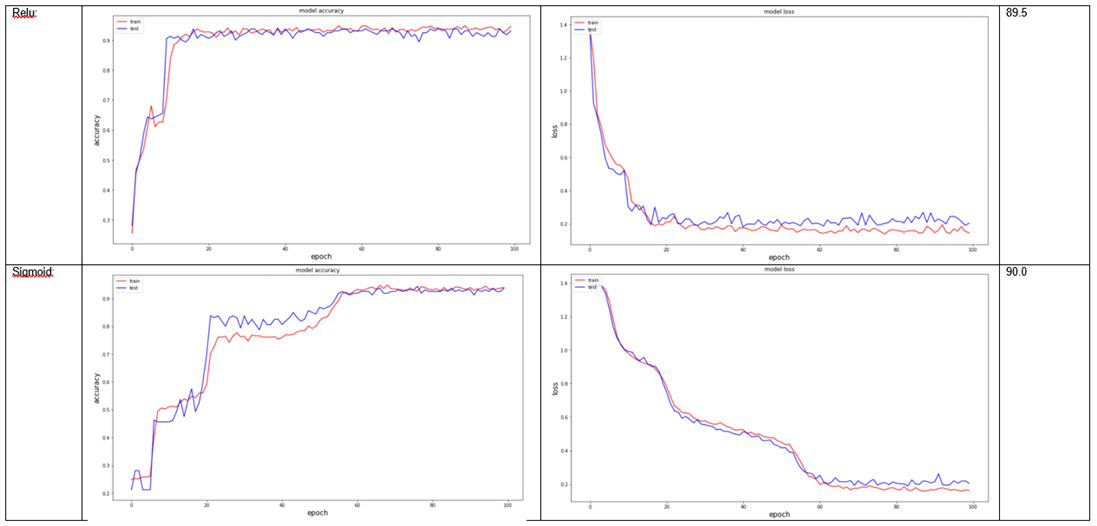
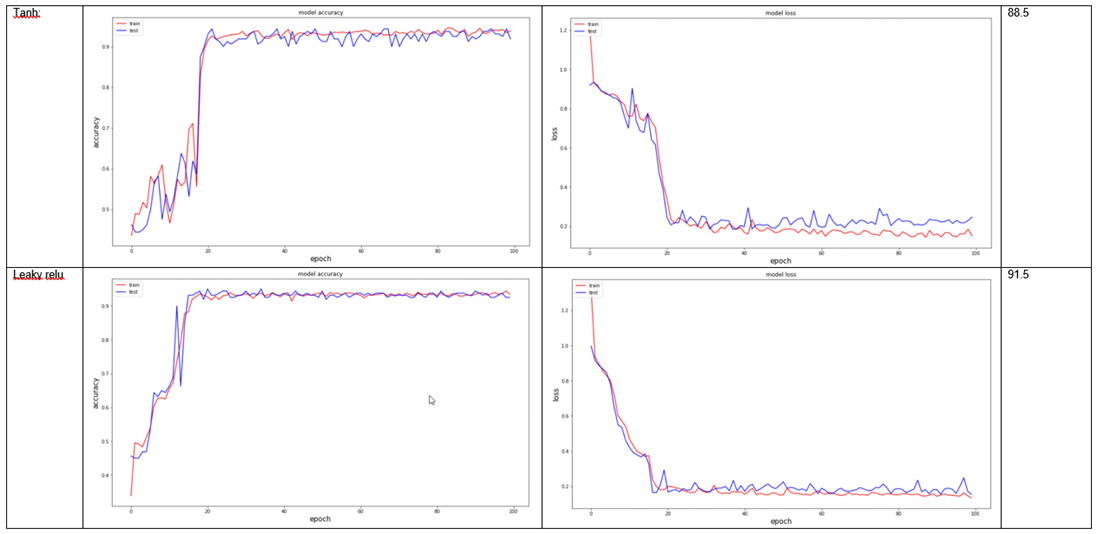

Conclusie: Relu en Leaky Relu geven de beste resultaten, waarbij Leaky relu nipt de betere is.  Sigmoid en Tanh hebben duidelijk meer epochs nodig om tot een gelijkaardig resultaat te komen.

8. Probeer verschillende initializers. (https://keras.io/initializers/)

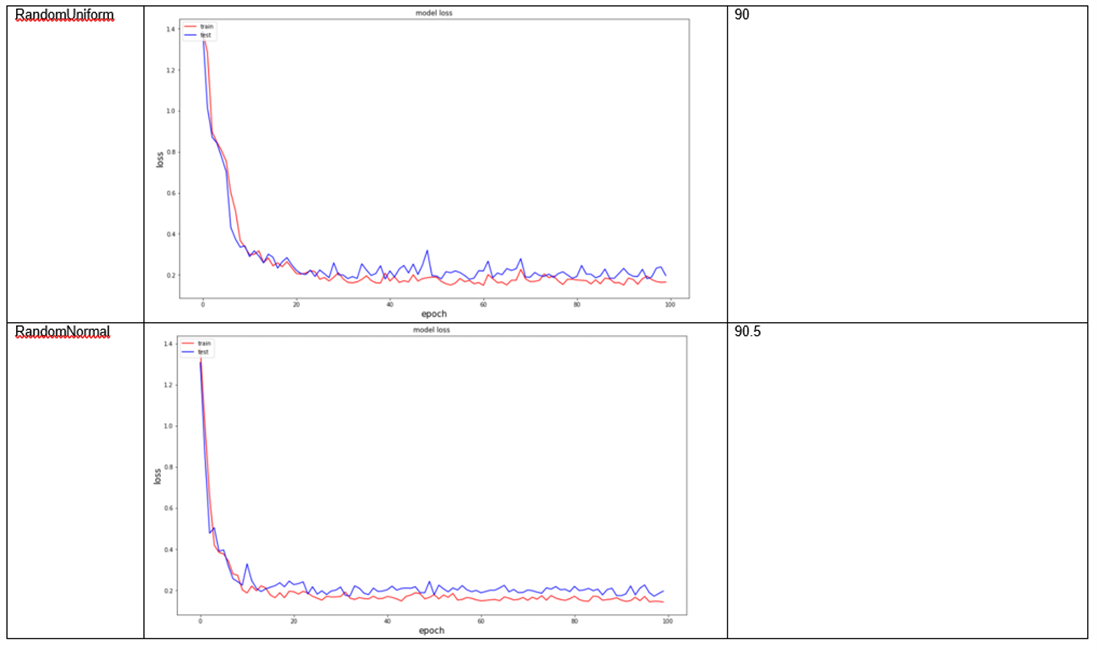
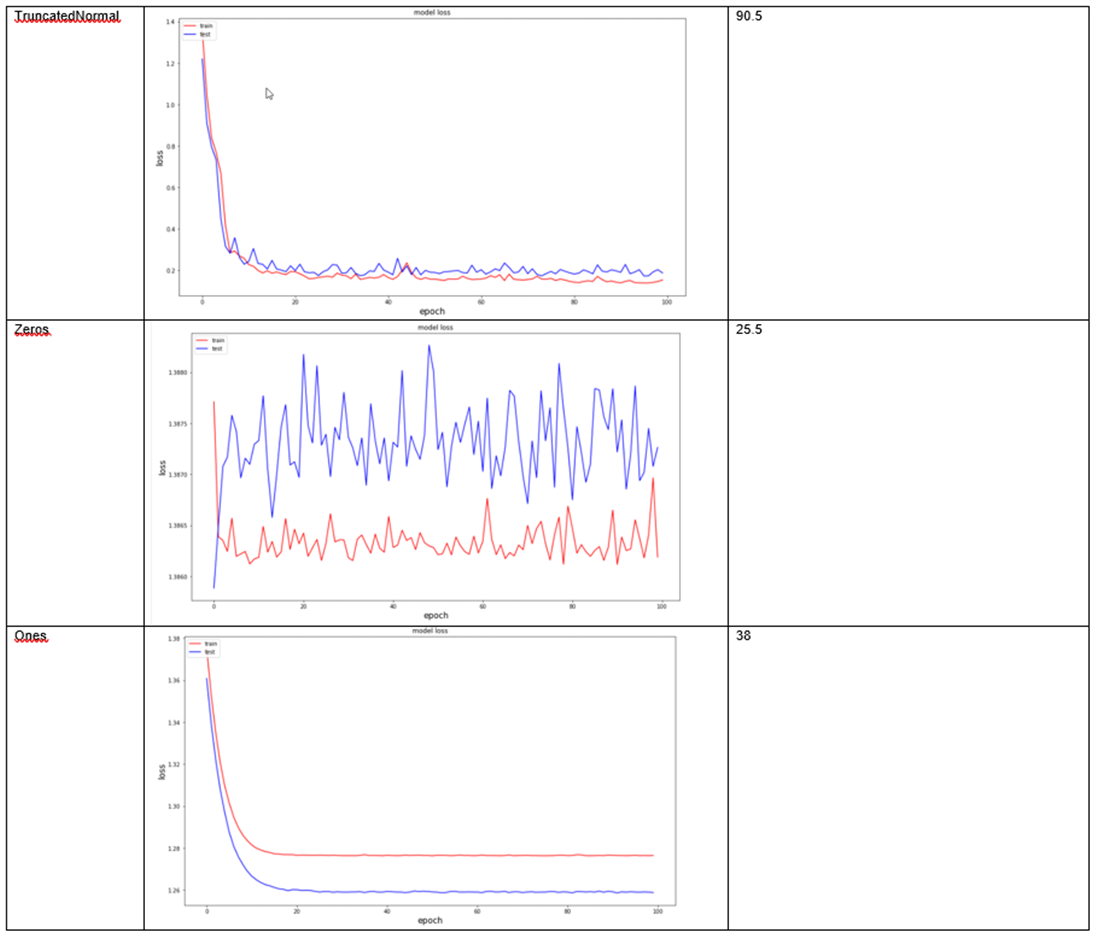
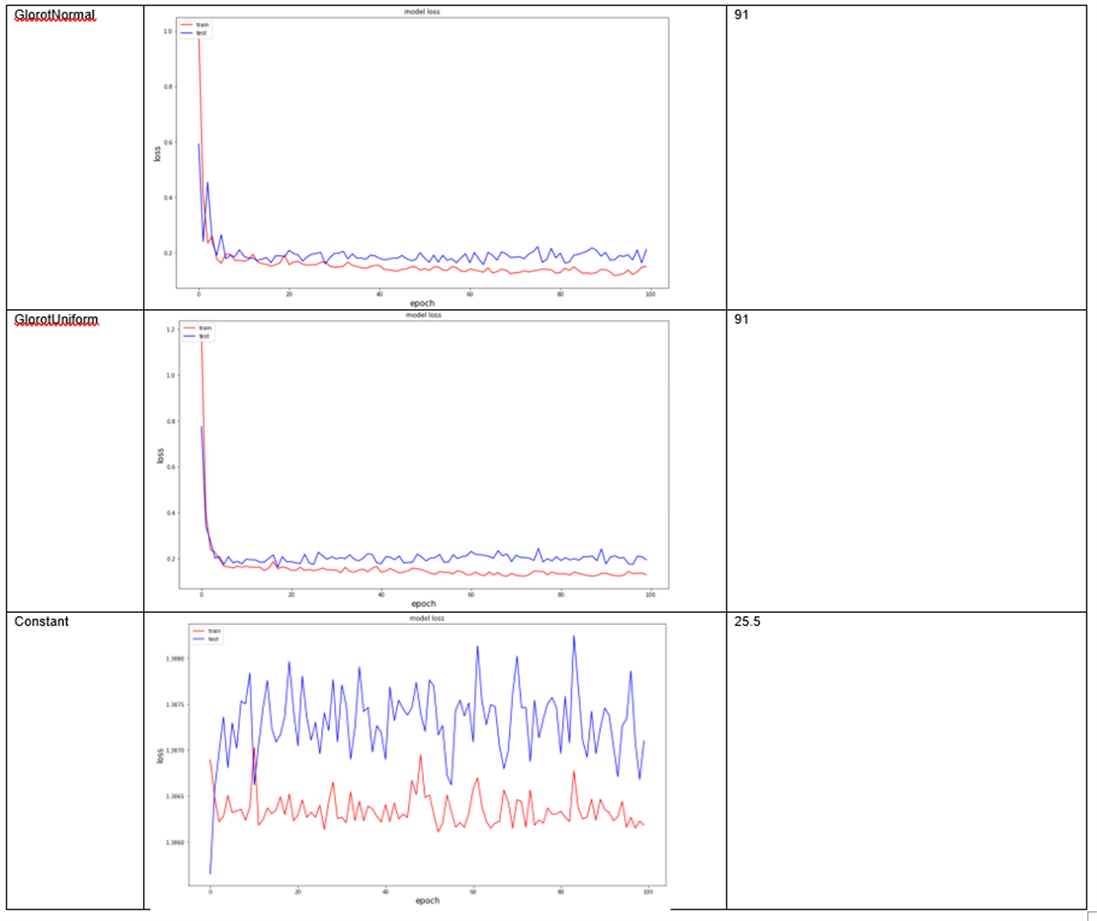

Conclusie: Veel verschillende initializers werken en geven ongeveer hetzelfde eindresultaat, maar zodra met constante waarden (ook met nullen of eenen) wordt gewerkt gaat de performantie drastisch achteruit.  Dit is omdat de neuronen dan allemaal hetzelfde doen, en we dus weinig voordeel hebben van het neuraal netwerk.

9. Doe hyperparameter tuning via grid search, random search en bayes optimization. Wat is de finale accuracy die je haalt op de test set?

In [15]:
# hyperparameter tuning via grid search

def create_model(optimizer='adam',activation = 'relu',dropout_rate = 0.0, kernel_initializer='uniform',neurons = 10):
    model = Sequential()
    model.add(Dense(neurons, input_dim=X_train.shape[1], kernel_initializer=kernel_initializer,activation="relu"))
    model.add(Dropout(dropout_rate))
    model.add(BatchNormalization())
    model.add(Dense(neurons, kernel_initializer=kernel_initializer,activation='relu'))
    model.add(Dropout(dropout_rate))
    model.add(BatchNormalization())
    model.add(Dense(neurons, kernel_initializer=kernel_initializer,activation='relu'))
    model.add(Dropout(dropout_rate))
    model.add(BatchNormalization())
    model.add(Dense(y_train.shape[1], activation='sigmoid'))

    model.compile(loss=tf.keras.losses.categorical_crossentropy,optimizer=optimizer,metrics=['accuracy']) 
    return model

In [16]:
from tensorflow.keras.wrappers.scikit_learn import KerasClassifier
from sklearn.model_selection import GridSearchCV


model = KerasClassifier(build_fn=create_model, batch_size=8, epochs =10)

input_dim= [X_train.shape[1]]
activation =  ['relu', 'tanh', 'sigmoid'] 
#learn_rate = [0.001, 0.01, 0.1, 0.2, 0.3]
dropout_rate = [0.0, 0.1, 0.5]
#weight_constraint=[1, 2, 3, 4, 5]
neurons = [5, 10, 20, 30, 40 ,50]
init = ['uniform', 'lecun_uniform', 'normal']
optimizer = [ 'SGD', 'adam']
#optimizer = [ 'SGD', 'RMSprop', 'Adagrad', 'Adadelta', 'Adam', 'Adamax', 'Nadam']

epochs = [50] 
batch_size = [8, 16, 32] 
param_grid = dict(epochs=epochs, batch_size=batch_size,optimizer = optimizer, dropout_rate = dropout_rate,activation = activation)
##############################################################
grid = GridSearchCV(estimator=model, param_grid = param_grid,verbose=1)
grid_result = grid.fit(X_train, y_train) 

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Epoch 1/50


<ipython-input-16-edf2cff1173f>:5: DeprecationWarning: KerasClassifier is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead. See https://www.adriangb.com/scikeras/stable/migration.html for help migrating.
  model = KerasClassifier(build_fn=create_model, batch_size=8, epochs =10)


80/80 [==============================] - 1s 2ms/step - loss: 0.6228 - accuracy: 0.8031
Epoch 2/50
80/80 [==============================] - 0s 2ms/step - loss: 0.4901 - accuracy: 0.8469
Epoch 3/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4269 - accuracy: 0.8766
Epoch 4/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4423 - accuracy: 0.8656
Epoch 5/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4180 - accuracy: 0.8609
Epoch 6/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4081 - accuracy: 0.8687
Epoch 7/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4098 - accuracy: 0.8703
Epoch 8/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3448 - accuracy: 0.9000
Epoch 9/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3334 - accuracy: 0.8953
Epoch 10/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3731 - accuracy: 0.8859
Epoch 11/50
80/80 [===========

80/80 [==============================] - 0s 3ms/step - loss: 0.3762 - accuracy: 0.8859
Epoch 15/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3703 - accuracy: 0.8859
Epoch 16/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3353 - accuracy: 0.8906
Epoch 17/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3146 - accuracy: 0.9062
Epoch 18/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3186 - accuracy: 0.9031
Epoch 19/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3330 - accuracy: 0.8859
Epoch 20/50
80/80 [==============================] - 0s 3ms/step - loss: 0.2693 - accuracy: 0.9187
Epoch 21/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3861 - accuracy: 0.8672
Epoch 22/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3244 - accuracy: 0.8891
Epoch 23/50
80/80 [==============================] - 0s 3ms/step - loss: 0.2875 - accuracy: 0.9031
Epoch 24/50
80/80 [===

80/80 [==============================] - 0s 2ms/step - loss: 0.2892 - accuracy: 0.9203
Epoch 47/50
80/80 [==============================] - 0s 3ms/step - loss: 0.2992 - accuracy: 0.9078
Epoch 48/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3164 - accuracy: 0.9000
Epoch 49/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3091 - accuracy: 0.8953
Epoch 50/50
20/20 [==============================] - 0s 1ms/step - loss: 0.2086 - accuracy: 0.9250
Epoch 1/50
80/80 [==============================] - 2s 3ms/step - loss: 0.7040 - accuracy: 0.7625
Epoch 2/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4278 - accuracy: 0.8703
Epoch 3/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3944 - accuracy: 0.8672
Epoch 4/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3327 - accuracy: 0.9016
Epoch 5/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3508 - accuracy: 0.8859
Epoch 6/50
80/80 [=========

...

20/20 [==============================] - 0s 3ms/step - loss: 0.2851 - accuracy: 0.9000
Epoch 41/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2549 - accuracy: 0.9125
Epoch 42/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2510 - accuracy: 0.9141
Epoch 43/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2529 - accuracy: 0.9109
Epoch 44/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2248 - accuracy: 0.9203
Epoch 45/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2603 - accuracy: 0.9094
Epoch 46/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2813 - accuracy: 0.8984
Epoch 47/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2940 - accuracy: 0.9062
Epoch 48/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2415 - accuracy: 0.9312
Epoch 49/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2245 - accuracy: 0.9219
Epoch 50/50
5/5 [=====

20/20 [==============================] - 0s 3ms/step - loss: 1.1227 - accuracy: 0.5000
Epoch 3/50
20/20 [==============================] - 0s 3ms/step - loss: 1.1705 - accuracy: 0.4953
Epoch 4/50
20/20 [==============================] - 0s 3ms/step - loss: 1.1174 - accuracy: 0.4953
Epoch 5/50
20/20 [==============================] - 0s 3ms/step - loss: 1.1158 - accuracy: 0.5109
Epoch 6/50
20/20 [==============================] - 0s 3ms/step - loss: 1.0596 - accuracy: 0.5594
Epoch 7/50
20/20 [==============================] - 0s 3ms/step - loss: 1.0952 - accuracy: 0.5516
Epoch 8/50
20/20 [==============================] - 0s 3ms/step - loss: 1.1121 - accuracy: 0.5344
Epoch 9/50
20/20 [==============================] - 0s 3ms/step - loss: 1.1554 - accuracy: 0.5063
Epoch 10/50
20/20 [==============================] - 0s 3ms/step - loss: 1.1049 - accuracy: 0.5562
Epoch 11/50
20/20 [==============================] - 0s 3ms/step - loss: 1.0408 - accuracy: 0.5703
Epoch 12/50
20/20 [==========

20/20 [==============================] - 0s 3ms/step - loss: 0.9100 - accuracy: 0.6375
Epoch 16/50
20/20 [==============================] - 0s 3ms/step - loss: 0.9351 - accuracy: 0.6125
Epoch 17/50
20/20 [==============================] - 0s 3ms/step - loss: 0.9293 - accuracy: 0.6031
Epoch 18/50
20/20 [==============================] - 0s 3ms/step - loss: 0.9285 - accuracy: 0.6062
Epoch 19/50
20/20 [==============================] - 0s 3ms/step - loss: 0.9485 - accuracy: 0.6187
Epoch 20/50
20/20 [==============================] - 0s 3ms/step - loss: 0.9347 - accuracy: 0.6297
Epoch 21/50
20/20 [==============================] - 0s 3ms/step - loss: 0.9029 - accuracy: 0.6313
Epoch 22/50
20/20 [==============================] - 0s 3ms/step - loss: 0.8785 - accuracy: 0.6344
Epoch 23/50
20/20 [==============================] - 0s 3ms/step - loss: 0.8878 - accuracy: 0.6484
Epoch 24/50
20/20 [==============================] - 0s 3ms/step - loss: 0.9276 - accuracy: 0.6203
Epoch 25/50
20/20 [===

20/20 [==============================] - 0s 3ms/step - loss: 0.9285 - accuracy: 0.6047
Epoch 48/50
20/20 [==============================] - 0s 3ms/step - loss: 0.9057 - accuracy: 0.5969
Epoch 49/50
20/20 [==============================] - 0s 3ms/step - loss: 0.8435 - accuracy: 0.6703
Epoch 50/50
5/5 [==============================] - 0s 2ms/step - loss: 0.5128 - accuracy: 0.9125
Epoch 1/50
20/20 [==============================] - 2s 3ms/step - loss: 1.6538 - accuracy: 0.2500
Epoch 2/50
20/20 [==============================] - 0s 3ms/step - loss: 1.3064 - accuracy: 0.3953
Epoch 3/50
20/20 [==============================] - 0s 3ms/step - loss: 1.2017 - accuracy: 0.4406
Epoch 4/50
20/20 [==============================] - 0s 3ms/step - loss: 1.1746 - accuracy: 0.4734
Epoch 5/50
20/20 [==============================] - 0s 3ms/step - loss: 1.1389 - accuracy: 0.5031
Epoch 6/50
20/20 [==============================] - 0s 3ms/step - loss: 1.1105 - accuracy: 0.5219
Epoch 7/50
20/20 [============

25/25 [==============================] - 0s 3ms/step - loss: 0.4144 - accuracy: 0.8737
Epoch 10/50
25/25 [==============================] - 0s 3ms/step - loss: 0.4037 - accuracy: 0.8800
Epoch 11/50
25/25 [==============================] - 0s 3ms/step - loss: 0.3821 - accuracy: 0.8850
Epoch 12/50
25/25 [==============================] - 0s 3ms/step - loss: 0.3923 - accuracy: 0.8888
Epoch 13/50
25/25 [==============================] - 0s 3ms/step - loss: 0.3657 - accuracy: 0.8950
Epoch 14/50
25/25 [==============================] - 0s 3ms/step - loss: 0.3924 - accuracy: 0.8875
Epoch 15/50
25/25 [==============================] - 0s 3ms/step - loss: 0.3906 - accuracy: 0.8825
Epoch 16/50
25/25 [==============================] - 0s 3ms/step - loss: 0.3833 - accuracy: 0.8763
Epoch 17/50
25/25 [==============================] - 0s 3ms/step - loss: 0.3729 - accuracy: 0.8850
Epoch 18/50
25/25 [==============================] - 0s 3ms/step - loss: 0.3591 - accuracy: 0.8963
Epoch 19/50
25/25 [===

In [17]:
print(f"Best: {grid_result.best_score_} using {grid_result.best_params_}")
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']

print("\n\nOverige resultaten:")
for mean, stdev, param in sorted(zip(means, stds, params), key=lambda x: x[0], reverse=True):
    print(f"\nMean: {mean}, Stdev: {stdev}, Using params: \n{param}")

Best: 0.9362500071525574 using {'activation': 'sigmoid', 'batch_size': 32, 'dropout_rate': 0.1, 'epochs': 50, 'optimizer': 'SGD'}


Overige resultaten:

Mean: 0.9362500071525574, Stdev: 0.0061237258169748576, Using params: 
{'activation': 'sigmoid', 'batch_size': 32, 'dropout_rate': 0.1, 'epochs': 50, 'optimizer': 'SGD'}

Mean: 0.9337500095367431, Stdev: 0.008477920212559532, Using params: 
{'activation': 'relu', 'batch_size': 32, 'dropout_rate': 0.0, 'epochs': 50, 'optimizer': 'adam'}

Mean: 0.9337499976158142, Stdev: 0.009354160034157547, Using params: 
{'activation': 'relu', 'batch_size': 8, 'dropout_rate': 0.1, 'epochs': 50, 'optimizer': 'adam'}

Mean: 0.9300000071525574, Stdev: 0.012747554161136754, Using params: 
{'activation': 'relu', 'batch_size': 16, 'dropout_rate': 0.0, 'epochs': 50, 'optimizer': 'SGD'}

Mean: 0.9300000071525574, Stdev: 0.015512091673246997, Using params: 
{'activation': 'tanh', 'batch_size': 8, 'dropout_rate': 0.1, 'epochs': 50, 'optimizer': 'adam'}

Mean: 0

In [18]:
# Train een Neuraal Netwerk via random search

from tensorflow.keras.wrappers.scikit_learn import KerasClassifier
from sklearn.model_selection import RandomizedSearchCV


model = KerasClassifier(build_fn=create_model, batch_size=8, epochs =10)


parameters = {'epochs' : [50], 
              'batch_size' : [8, 16, 32],
              'optimizer' : [ 'SGD', 'adam'],
              'dropout_rate' : [0.0, 0.1, 0.5],
              'activation' :  ['relu', 'tanh', 'sigmoid']
             }
              
input_dim= [X_train.shape[1]]

n_iter_search = 40
grid = RandomizedSearchCV(estimator=model, param_distributions = parameters,n_iter=n_iter_search, verbose=1)
grid_result = grid.fit(X_train, y_train) 

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Epoch 1/50


<ipython-input-18-5afdcdf8d7b9>:7: DeprecationWarning: KerasClassifier is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead. See https://www.adriangb.com/scikeras/stable/migration.html for help migrating.
  model = KerasClassifier(build_fn=create_model, batch_size=8, epochs =10)


40/40 [==============================] - 1s 3ms/step - loss: 0.4410 - accuracy: 0.8719
Epoch 2/50
40/40 [==============================] - 0s 3ms/step - loss: 0.4018 - accuracy: 0.8875
Epoch 3/50
40/40 [==============================] - 0s 3ms/step - loss: 0.3546 - accuracy: 0.9031
Epoch 4/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2724 - accuracy: 0.9109
Epoch 5/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2789 - accuracy: 0.9187
Epoch 6/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2713 - accuracy: 0.9234
Epoch 7/50
40/40 [==============================] - 0s 3ms/step - loss: 0.3005 - accuracy: 0.9000
Epoch 8/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2645 - accuracy: 0.9328
Epoch 9/50
40/40 [==============================] - 0s 3ms/step - loss: 0.3051 - accuracy: 0.8969
Epoch 10/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2684 - accuracy: 0.9250
Epoch 11/50
40/40 [===========

40/40 [==============================] - 0s 3ms/step - loss: 0.2702 - accuracy: 0.8938
Epoch 15/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2921 - accuracy: 0.9172
Epoch 16/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2282 - accuracy: 0.9312
Epoch 17/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2463 - accuracy: 0.9141
Epoch 18/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2439 - accuracy: 0.9156
Epoch 19/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2623 - accuracy: 0.9062
Epoch 20/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2228 - accuracy: 0.9344
Epoch 21/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2579 - accuracy: 0.9156
Epoch 22/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2671 - accuracy: 0.9203
Epoch 23/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2647 - accuracy: 0.9047
Epoch 24/50
40/40 [===

40/40 [==============================] - 0s 3ms/step - loss: 0.2105 - accuracy: 0.9203
Epoch 47/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2208 - accuracy: 0.9141
Epoch 48/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2061 - accuracy: 0.9234
Epoch 49/50
40/40 [==============================] - 0s 3ms/step - loss: 0.1966 - accuracy: 0.9344
Epoch 50/50
10/10 [==============================] - 0s 2ms/step - loss: 0.1675 - accuracy: 0.9312
Epoch 1/50
20/20 [==============================] - 1s 3ms/step - loss: 0.5706 - accuracy: 0.8141
Epoch 2/50
20/20 [==============================] - 0s 3ms/step - loss: 0.3439 - accuracy: 0.9078
Epoch 3/50
20/20 [==============================] - 0s 3ms/step - loss: 0.3002 - accuracy: 0.9094
Epoch 4/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2685 - accuracy: 0.9281
Epoch 5/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2694 - accuracy: 0.9266
Epoch 6/50
20/20 [=========

...

80/80 [==============================] - 0s 3ms/step - loss: 0.5011 - accuracy: 0.8266
Epoch 42/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4427 - accuracy: 0.8578
Epoch 43/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4997 - accuracy: 0.8469
Epoch 44/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4830 - accuracy: 0.8297
Epoch 45/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4695 - accuracy: 0.8391
Epoch 46/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4446 - accuracy: 0.8562
Epoch 47/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4969 - accuracy: 0.8359
Epoch 48/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4873 - accuracy: 0.8172
Epoch 49/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4763 - accuracy: 0.8266
Epoch 50/50
20/20 [==============================] - 0s 1ms/step - loss: 0.2559 - accuracy: 0.9000
Epoch 1/50
80/80 [====

80/80 [==============================] - 0s 3ms/step - loss: 1.2711 - accuracy: 0.4047
Epoch 4/50
80/80 [==============================] - 0s 3ms/step - loss: 1.2745 - accuracy: 0.3844
Epoch 5/50
80/80 [==============================] - 0s 3ms/step - loss: 1.2330 - accuracy: 0.4656
Epoch 6/50
80/80 [==============================] - 0s 3ms/step - loss: 1.2314 - accuracy: 0.4422
Epoch 7/50
80/80 [==============================] - 0s 3ms/step - loss: 1.2545 - accuracy: 0.4297
Epoch 8/50
80/80 [==============================] - 0s 3ms/step - loss: 1.2076 - accuracy: 0.4391
Epoch 9/50
80/80 [==============================] - 0s 3ms/step - loss: 1.2222 - accuracy: 0.4688
Epoch 10/50
80/80 [==============================] - 0s 3ms/step - loss: 1.1867 - accuracy: 0.4422
Epoch 11/50
80/80 [==============================] - 0s 3ms/step - loss: 1.1904 - accuracy: 0.4406
Epoch 12/50
80/80 [==============================] - 0s 3ms/step - loss: 1.1447 - accuracy: 0.5141
Epoch 13/50
80/80 [=========

20/20 [==============================] - 0s 3ms/step - loss: 0.2161 - accuracy: 0.9297
Epoch 17/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2195 - accuracy: 0.9172
Epoch 18/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2079 - accuracy: 0.9281
Epoch 19/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2000 - accuracy: 0.9297
Epoch 20/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2001 - accuracy: 0.9250
Epoch 21/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2236 - accuracy: 0.9266
Epoch 22/50
20/20 [==============================] - 0s 3ms/step - loss: 0.1901 - accuracy: 0.9312
Epoch 23/50
20/20 [==============================] - 0s 3ms/step - loss: 0.1993 - accuracy: 0.9266
Epoch 24/50
20/20 [==============================] - 0s 3ms/step - loss: 0.1988 - accuracy: 0.9359
Epoch 25/50
20/20 [==============================] - 0s 3ms/step - loss: 0.1854 - accuracy: 0.9359
Epoch 26/50
20/20 [===

20/20 [==============================] - 0s 3ms/step - loss: 0.1871 - accuracy: 0.9375
Epoch 49/50
20/20 [==============================] - 0s 3ms/step - loss: 0.1986 - accuracy: 0.9266
Epoch 50/50
5/5 [==============================] - 0s 2ms/step - loss: 0.1919 - accuracy: 0.9312
Epoch 1/50
20/20 [==============================] - 2s 3ms/step - loss: 0.8358 - accuracy: 0.7422
Epoch 2/50
20/20 [==============================] - 0s 3ms/step - loss: 0.5256 - accuracy: 0.9172
Epoch 3/50
20/20 [==============================] - 0s 3ms/step - loss: 0.3928 - accuracy: 0.9250
Epoch 4/50
20/20 [==============================] - 0s 3ms/step - loss: 0.3450 - accuracy: 0.9125
Epoch 5/50
20/20 [==============================] - 0s 3ms/step - loss: 0.3095 - accuracy: 0.9297
Epoch 6/50
20/20 [==============================] - 0s 3ms/step - loss: 0.3072 - accuracy: 0.9109
Epoch 7/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2907 - accuracy: 0.9187
Epoch 8/50
20/20 [=============

100/100 [==============================] - 0s 3ms/step - loss: 0.4542 - accuracy: 0.8400
Epoch 11/50
100/100 [==============================] - 0s 3ms/step - loss: 0.4175 - accuracy: 0.8712
Epoch 12/50
100/100 [==============================] - 0s 3ms/step - loss: 0.3994 - accuracy: 0.8700
Epoch 13/50
100/100 [==============================] - 0s 3ms/step - loss: 0.3780 - accuracy: 0.8763
Epoch 14/50
100/100 [==============================] - 0s 3ms/step - loss: 0.3869 - accuracy: 0.8737
Epoch 15/50
100/100 [==============================] - 0s 3ms/step - loss: 0.4367 - accuracy: 0.8450
Epoch 16/50
100/100 [==============================] - 0s 3ms/step - loss: 0.4030 - accuracy: 0.8687
Epoch 17/50
100/100 [==============================] - 0s 3ms/step - loss: 0.4247 - accuracy: 0.8625
Epoch 18/50
100/100 [==============================] - 0s 3ms/step - loss: 0.4251 - accuracy: 0.8637
Epoch 19/50
100/100 [==============================] - 0s 3ms/step - loss: 0.4122 - accuracy: 0.8462
Ep

In [19]:
print(f"Best: {grid_result.best_score_} using {grid_result.best_params_}")
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in sorted(zip(means, stds, params), key=lambda x: x[0], reverse=True):
    print(f"\n{mean}, {stdev} with: {param}")

Best: 0.9362499952316284 using {'optimizer': 'adam', 'epochs': 50, 'dropout_rate': 0.1, 'batch_size': 8, 'activation': 'sigmoid'}

0.9362499952316284, 0.004677089575080179 with: {'optimizer': 'adam', 'epochs': 50, 'dropout_rate': 0.1, 'batch_size': 8, 'activation': 'sigmoid'}

0.9362499952316284, 0.011456430913043616 with: {'optimizer': 'adam', 'epochs': 50, 'dropout_rate': 0.0, 'batch_size': 8, 'activation': 'sigmoid'}

0.9349999904632569, 0.008477909666685383 with: {'optimizer': 'SGD', 'epochs': 50, 'dropout_rate': 0.0, 'batch_size': 8, 'activation': 'tanh'}

0.9349999904632569, 0.005000019073486328 with: {'optimizer': 'adam', 'epochs': 50, 'dropout_rate': 0.0, 'batch_size': 32, 'activation': 'sigmoid'}

0.9325000166893005, 0.012119199151724588 with: {'optimizer': 'adam', 'epochs': 50, 'dropout_rate': 0.0, 'batch_size': 8, 'activation': 'relu'}

0.9324999928474427, 0.010752904643718201 with: {'optimizer': 'SGD', 'epochs': 50, 'dropout_rate': 0.1, 'batch_size': 16, 'activation': 'tanh

In [20]:
### Train een Neuraal Netwerk via Bayes Search: ZONDER GPU!!!

from tensorflow.keras.wrappers.scikit_learn import KerasClassifier
from skopt import BayesSearchCV


model = KerasClassifier(build_fn=create_model, batch_size=8, epochs =10)


parameters = {'epochs' : [50], 
              'batch_size' : [8, 16, 32],
              'optimizer' : [ 'SGD', 'adam'],
              'dropout_rate' : [0.0, 0.1, 0.5],
              'activation' :  ['relu', 'tanh', 'sigmoid']
             }
              
input_dim= [X_train.shape[1]]

n_iter_search = 40
Bayes_search = BayesSearchCV(estimator=model, search_spaces = parameters,n_iter=n_iter_search, verbose=1)#,n_jobs = -1)
Bayes_result = Bayes_search.fit(X_train, y_train) 

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Epoch 1/50


<ipython-input-20-6848cc3684c1>:7: DeprecationWarning: KerasClassifier is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead. See https://www.adriangb.com/scikeras/stable/migration.html for help migrating.
  model = KerasClassifier(build_fn=create_model, batch_size=8, epochs =10)


20/20 [==============================] - 1s 3ms/step - loss: 0.4518 - accuracy: 0.8687
Epoch 2/50
20/20 [==============================] - 0s 3ms/step - loss: 0.3461 - accuracy: 0.8828
Epoch 3/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2662 - accuracy: 0.9187
Epoch 4/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2497 - accuracy: 0.9344
Epoch 5/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2631 - accuracy: 0.9187
Epoch 6/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2686 - accuracy: 0.9047
Epoch 7/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2509 - accuracy: 0.9219
Epoch 8/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2735 - accuracy: 0.9062
Epoch 9/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2322 - accuracy: 0.9234
Epoch 10/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2419 - accuracy: 0.9250
Epoch 11/50
20/20 [===========

20/20 [==============================] - 0s 3ms/step - loss: 0.2419 - accuracy: 0.9344
Epoch 15/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2394 - accuracy: 0.9234
Epoch 16/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2539 - accuracy: 0.9266
Epoch 17/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2297 - accuracy: 0.9297
Epoch 18/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2467 - accuracy: 0.9219
Epoch 19/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2414 - accuracy: 0.9234
Epoch 20/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2350 - accuracy: 0.9234
Epoch 21/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2375 - accuracy: 0.9141
Epoch 22/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2284 - accuracy: 0.9312
Epoch 23/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2439 - accuracy: 0.9094
Epoch 24/50
20/20 [===

20/20 [==============================] - 0s 3ms/step - loss: 0.2204 - accuracy: 0.9250
Epoch 47/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2200 - accuracy: 0.9234
Epoch 48/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2014 - accuracy: 0.9234
Epoch 49/50
20/20 [==============================] - 0s 3ms/step - loss: 0.2005 - accuracy: 0.9359
Epoch 50/50
5/5 [==============================] - 0s 2ms/step - loss: 0.1887 - accuracy: 0.9375
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Epoch 1/50
80/80 [==============================] - 1s 3ms/step - loss: 0.5991 - accuracy: 0.8031
Epoch 2/50
80/80 [==============================] - 0s 3ms/step - loss: 0.5012 - accuracy: 0.8281
Epoch 3/50
80/80 [==============================] - 0s 3ms/step - loss: 0.4603 - accuracy: 0.8609
Epoch 4/50
80/80 [==============================] - 0s 3ms/step - loss: 0.3866 - accuracy: 0.8828
Epoch 5/50
80/80 [==============================] - 0s 3ms/step - lo

...

10/10 [==============================] - 0s 1ms/step - loss: 0.1971 - accuracy: 0.9062
Epoch 1/50
40/40 [==============================] - 2s 3ms/step - loss: 0.8483 - accuracy: 0.6797
Epoch 2/50
40/40 [==============================] - 0s 3ms/step - loss: 0.5508 - accuracy: 0.8234
Epoch 3/50
40/40 [==============================] - 0s 3ms/step - loss: 0.5295 - accuracy: 0.8250
Epoch 4/50
40/40 [==============================] - 0s 3ms/step - loss: 0.3963 - accuracy: 0.8687
Epoch 5/50
40/40 [==============================] - 0s 3ms/step - loss: 0.4995 - accuracy: 0.8484
Epoch 6/50
40/40 [==============================] - 0s 3ms/step - loss: 0.4759 - accuracy: 0.8453
Epoch 7/50
40/40 [==============================] - 0s 3ms/step - loss: 0.3852 - accuracy: 0.8828
Epoch 8/50
40/40 [==============================] - 0s 3ms/step - loss: 0.3909 - accuracy: 0.8766
Epoch 9/50
40/40 [==============================] - 0s 3ms/step - loss: 0.4498 - accuracy: 0.8375
Epoch 10/50
40/40 [============

/usr/local/lib/python3.8/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point ['tanh', 32, 0.1, 50, 'adam'] before, using random point ['sigmoid', 16, 0.0, 50, 'adam']
  warnings.warn(


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Epoch 1/50
40/40 [==============================] - 2s 2ms/step - loss: 0.7637 - accuracy: 0.7281
Epoch 2/50
40/40 [==============================] - 0s 2ms/step - loss: 0.3993 - accuracy: 0.8984
Epoch 3/50
40/40 [==============================] - 0s 2ms/step - loss: 0.3113 - accuracy: 0.9156
Epoch 4/50
40/40 [==============================] - 0s 2ms/step - loss: 0.3113 - accuracy: 0.9078
Epoch 5/50
40/40 [==============================] - 0s 3ms/step - loss: 0.3163 - accuracy: 0.9141
Epoch 6/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2957 - accuracy: 0.9062
Epoch 7/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2885 - accuracy: 0.8984
Epoch 8/50
40/40 [==============================] - 0s 2ms/step - loss: 0.2764 - accuracy: 0.9016
Epoch 9/50
40/40 [==============================] - 0s 3ms/step - loss: 0.3188 - accuracy: 0.9016
Epoch 10/50
40/40 [==============================] - 0s 2ms

40/40 [==============================] - 0s 3ms/step - loss: 0.2399 - accuracy: 0.9172
Epoch 14/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2272 - accuracy: 0.9250
Epoch 15/50
40/40 [==============================] - 0s 2ms/step - loss: 0.2482 - accuracy: 0.9094
Epoch 16/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2243 - accuracy: 0.9219
Epoch 17/50
40/40 [==============================] - 0s 4ms/step - loss: 0.2092 - accuracy: 0.9141
Epoch 18/50
40/40 [==============================] - 0s 4ms/step - loss: 0.2256 - accuracy: 0.9219
Epoch 19/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2350 - accuracy: 0.9141
Epoch 20/50
40/40 [==============================] - 0s 3ms/step - loss: 0.1986 - accuracy: 0.9281
Epoch 21/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2214 - accuracy: 0.9234
Epoch 22/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2543 - accuracy: 0.9078
Epoch 23/50
40/40 [===

40/40 [==============================] - 0s 3ms/step - loss: 0.2208 - accuracy: 0.9172
Epoch 46/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2021 - accuracy: 0.9172
Epoch 47/50
40/40 [==============================] - 0s 4ms/step - loss: 0.2008 - accuracy: 0.9250
Epoch 48/50
40/40 [==============================] - 0s 3ms/step - loss: 0.1847 - accuracy: 0.9281
Epoch 49/50
40/40 [==============================] - 0s 3ms/step - loss: 0.2261 - accuracy: 0.9109
Epoch 50/50
10/10 [==============================] - 0s 1ms/step - loss: 0.1775 - accuracy: 0.9187
Epoch 1/50
25/25 [==============================] - 1s 2ms/step - loss: 0.4996 - accuracy: 0.8687
Epoch 2/50
25/25 [==============================] - 0s 3ms/step - loss: 0.3416 - accuracy: 0.9087
Epoch 3/50
25/25 [==============================] - 0s 3ms/step - loss: 0.3052 - accuracy: 0.9187
Epoch 4/50
25/25 [==============================] - 0s 3ms/step - loss: 0.2804 - accuracy: 0.9225
Epoch 5/50
25/25 [========

In [21]:
print(f"Best: {Bayes_result.best_score_} using {Bayes_result.best_params_}")
means = Bayes_result.cv_results_['mean_test_score']
stds = Bayes_result.cv_results_['std_test_score']
params = Bayes_result.cv_results_['params']
print("\n\nOverige resultaten:")
for mean, stdev, param in sorted(zip(means, stds, params), key=lambda x: x[0], reverse=True):
    print(f"\n{mean}, {stdev} with: {param}")

Best: 0.9362500071525574 using OrderedDict([('activation', 'relu'), ('batch_size', 32), ('dropout_rate', 0.0), ('epochs', 50), ('optimizer', 'SGD')])


Overige resultaten:

0.9362500071525574, 0.007288699272915662 with: OrderedDict([('activation', 'relu'), ('batch_size', 32), ('dropout_rate', 0.0), ('epochs', 50), ('optimizer', 'SGD')])

0.9350000023841858, 0.006373780002935765 with: OrderedDict([('activation', 'relu'), ('batch_size', 16), ('dropout_rate', 0.0), ('epochs', 50), ('optimizer', 'SGD')])

0.9349999904632569, 0.005000019073486329 with: OrderedDict([('activation', 'sigmoid'), ('batch_size', 32), ('dropout_rate', 0.1), ('epochs', 50), ('optimizer', 'SGD')])

0.9337499976158142, 0.00499999821187398 with: OrderedDict([('activation', 'tanh'), ('batch_size', 32), ('dropout_rate', 0.1), ('epochs', 50), ('optimizer', 'adam')])

0.9325000047683716, 0.009185593997713527 with: OrderedDict([('activation', 'relu'), ('batch_size', 8), ('dropout_rate', 0.0), ('epochs', 50), ('optimizer', 

### Conclusie Grid Search - Random Search - Bayes Search:
Grid Search best: 0.936250 using {'activation': 'relu', 'batch_size': 8, 'dropout_rate': 0.1, 'epochs': 50, 'optimizer': 'SGD'} 
Random Search best: Best: 0.935000 using {'optimizer': 'adam', 'epochs': 50, 'dropout_rate': 0.0, 'batch_size': 8, 'activation': 'sigmoid'}
Bayes Search best: 0.936250 using OrderedDict([('activation', 'tanh'), ('batch_size', 32), ('dropout_rate', 0.0), ('epochs', 50), ('optimizer', 'SGD')])

De drie search methodes komen allen bijna tot een zelfde resultaat; de dropout rate is steeds laag bij elk resultaat; de activation is 3 keer anders (relu - sigmoid - tanh) en verschillende andere parameters zijn ook verschillend.

Deze technieken vragen wel relatief veel tijd om te trainen, en het resultaat wat hogerop werd bekomen zonder deze technieken draaide ook al om en bij de 90%.  Voor kleine netwerken die snel trainen kan Grid, Random of Bayes search een optie zijn, maar voor grote netwerken lijkt het een onbegonnen werk om op deze manier de hyperparameter tuning te doen wegens te lange trainingstijd.


## Customer satisfaction

Een bank probeert vroegtijdig ontevreden klanten op te sporen en wil daarvoor deep learning toepassen.
Gegeven is een dataset "customersatisfaction.csv" met geanonimiseerde gegevens van hun klanten en de bijhorende klantentevredenheid. De features zelf werden ook geanonimiseerd.
De target kolom is de variabele die voorspeld moet worden. 1 staat voor ontevreden klanten, 0 staat voor tevreden klanten.

Train een neuraal netwerk dat een zo hoog mogelijke accuraatheid haalt. 
Zorg dat er 10000 samples in de test set aanwezig zijn en zet de random_state op 0.

In [22]:
dataset = pd.read_csv('../DATA/customersatisfaction.csv')

dataset.head(10)

,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
0,1,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,39205.170000,0
1,3,2,34,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,49278.030000,0
2,4,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,67333.770000,0
3,8,2,37,0.0,195.0,195.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,64007.970000,0
4,10,2,39,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117310.979016,0
5,13,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,87975.750000,0
6,14,2,27,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94956.660000,0
7,18,2,26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,251638.950000,0
8,20,2,45,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,101962.020000,0
9,23,2,25,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,356463.060000,0


### zijn er features die allemaal nul zijn? (lege kolommen) Zo ja, verwijderen...

In [23]:
columns = dataset.columns
columns
lege = []

for column in columns:
    if dataset[column].mean() == 0:
        lege.append(column)
print (lege)        
for leeg in lege:
    dataset = dataset.drop(leeg, axis=1)

['ind_var2_0', 'ind_var2', 'ind_var27_0', 'ind_var28_0', 'ind_var28', 'ind_var27', 'ind_var41', 'ind_var46_0', 'ind_var46', 'num_var27_0', 'num_var28_0', 'num_var28', 'num_var27', 'num_var41', 'num_var46_0', 'num_var46', 'saldo_var28', 'saldo_var27', 'saldo_var41', 'saldo_var46', 'imp_amort_var18_hace3', 'imp_amort_var34_hace3', 'imp_reemb_var13_hace3', 'imp_reemb_var33_hace3', 'imp_trasp_var17_out_hace3', 'imp_trasp_var33_out_hace3', 'num_var2_0_ult1', 'num_var2_ult1', 'num_reemb_var13_hace3', 'num_reemb_var33_hace3', 'num_trasp_var17_out_hace3', 'num_trasp_var33_out_hace3', 'saldo_var2_ult1', 'saldo_medio_var13_medio_hace3']


In [24]:
dataset4smote = dataset
dataset.describe()

,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
count,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,...,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,7.602000e+04,76020.000000
mean,75964.050723,-1523.199277,33.212865,86.208265,72.363067,119.529632,3.559130,6.472698,0.412946,0.567352,...,7.935824,1.365146,12.215580,8.784074,31.505324,1.858575,76.026165,56.614351,1.172358e+05,0.039569
std,43781.947379,39033.462364,12.956486,1614.757313,339.315831,546.266294,93.155749,153.737066,30.604864,36.513513,...,455.887218,113.959637,783.207399,538.439211,2013.125393,147.786584,4040.337842,2852.579397,1.826646e+05,0.194945
min,1.000000,-999999.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.163750e+03,0.000000
25%,38104.750000,2.000000,23.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.787061e+04,0.000000
50%,76043.000000,2.000000,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.064092e+05,0.000000
75%,113748.750000,2.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.187563e+05,0.000000
max,151838.000000,238.000000,105.000000,210000.000000,12888.030000,21024.810000,8237.820000,11073.570000,6600.000000,6600.000000,...,50003.880000,20385.720000,138831.630000,91778.730000,438329.220000,24650.010000,681462.900000,397884.300000,2.203474e+07,1.000000


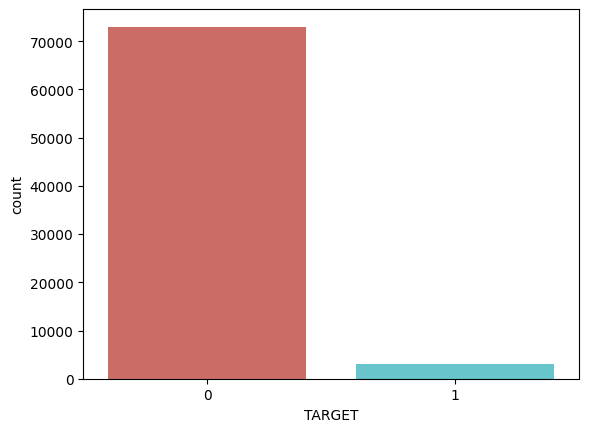

In [25]:
# Is de dataset gebalanceerd?
dataset.TARGET.value_counts()
sns.countplot(x = 'TARGET', data = dataset, palette = 'hls', hue='TARGET', legend=False) 
plt.show()

## De dataset is duidelijk niet gebalanceerd: bijna alle klanten zijn tevreden! De mate van onbalans is heel sterk.

## Data exploration

### Zijn er ontbrekende waarden?

In [26]:
leeg = dataset.isnull().sum()

#### Er zijn geen ontbrekende waarden

In [27]:
# dataset.corr()

### Hoe zit de correlatie van de features tov het target?

In [28]:
correlations = dataset.corr()['TARGET'][:-1].sort_values()

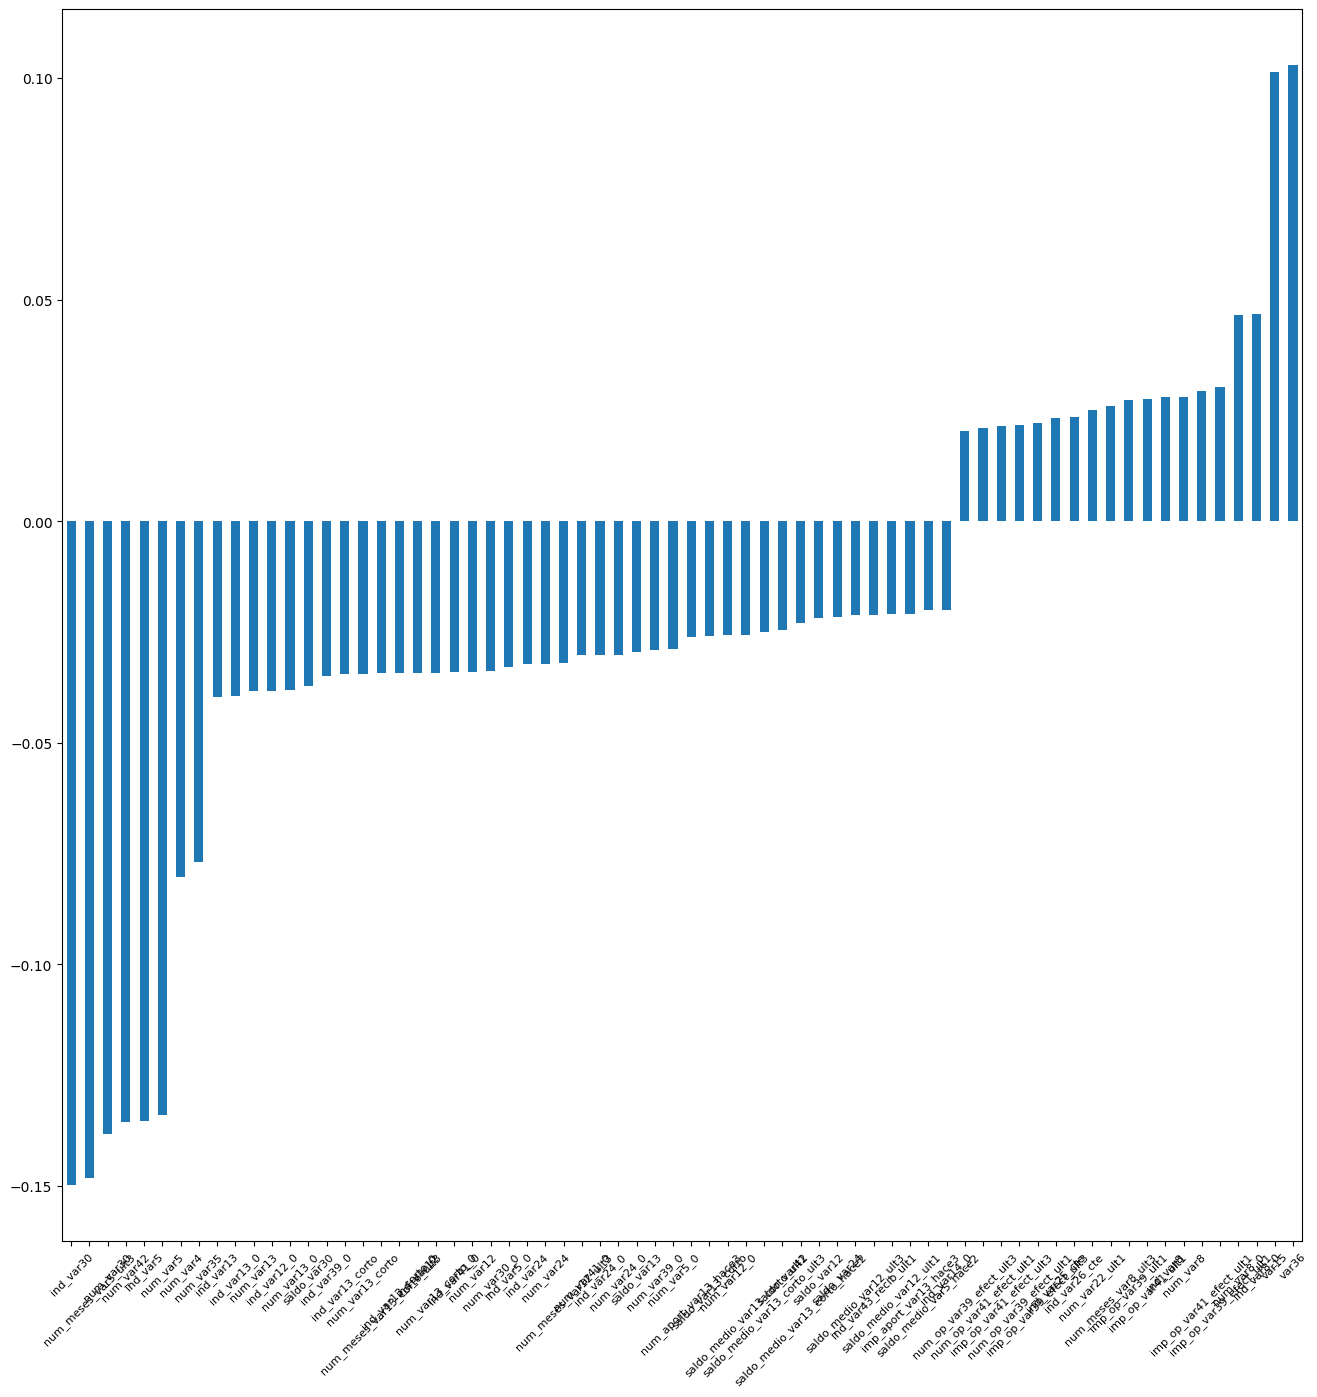

In [29]:
# filter de dataset om enkel correlaties boven een bepaalde treshold te behouden

treshold = 0.020

filtered_correlations = correlations[(correlations>treshold) | (correlations < -treshold)]
plt.figure(figsize=(16,16))
filtered_correlations.plot(kind='bar')
plt.xticks(rotation=45, fontsize=8)
plt.show()

In [30]:
# sns.pairplot(dataset)

## Data preprocessing

In [31]:
# Features en targets splitsen
features = list(dataset.columns[:dataset.columns.size-1])
X = dataset[features].values
y = dataset['TARGET'].values

In [32]:
# Splits op in training set en test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 10000, random_state =0)

# Converteer naar een numpy array
# X_train = X_train.values
# X_test = X_test.values

# One-hot encoding van de targets
y_train_orig= y_train
y_train = to_categorical(y_train)

y_test_orig = y_test
y_test = to_categorical(y_test)

# normaliseren van de features
# via robustscaler: This Scaler removes the median and scales the data according to the quantile range 
# from sklearn.preprocessing import MinMaxScaler
# scaler = MinMaxScaler()
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# from sklearn.preprocessing import RobustScaler
# Rscaler = RobustScaler()
# Rscaler.fit(X_train)

# X_train = Rscaler.transform(X_train)
# X_test = Rscaler.transform(X_test)

In [33]:
print (X_train.shape)
print (y_train.shape)

(66020, 336)
(66020, 2)


### Predictie met behulp van een neuraal netwerk

In [34]:
## parameters van het NN
model = Sequential()
dropoutrate = 0.3
batchsize = 16
inputdim = X_train.shape[1]  #336 input features

# model
model.add(Dense(20, input_dim=inputdim, kernel_initializer='uniform',activation='relu'))
model.add(Dropout(dropoutrate))
model.add(BatchNormalization())

model.add(Dense(2, activation='softmax'))

model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

# Trainen van het model
history = model.fit(X_train, y_train, epochs=10,validation_data=(X_test, y_test), validation_split=0.3, batch_size=batchsize, verbose=1)

Epoch 1/10
4127/4127 [==============================] - 10s 2ms/step - loss: 0.1863 - accuracy: 0.9501 - val_loss: 206136.1875 - val_accuracy: 0.9553
Epoch 2/10
4127/4127 [==============================] - 10s 2ms/step - loss: 0.1490 - accuracy: 0.9608 - val_loss: 0.1891 - val_accuracy: 0.9560
Epoch 3/10
4127/4127 [==============================] - 9s 2ms/step - loss: 0.1462 - accuracy: 0.9609 - val_loss: 0.1680 - val_accuracy: 0.9571
Epoch 4/10
4127/4127 [==============================] - 9s 2ms/step - loss: 0.1445 - accuracy: 0.9609 - val_loss: 0.1680 - val_accuracy: 0.9570
Epoch 5/10
4127/4127 [==============================] - 9s 2ms/step - loss: 0.1443 - accuracy: 0.9609 - val_loss: 0.1738 - val_accuracy: 0.9566
Epoch 6/10
4127/4127 [==============================] - 9s 2ms/step - loss: 0.1432 - accuracy: 0.9609 - val_loss: 0.1682 - val_accuracy: 0.9572
Epoch 7/10
4127/4127 [==============================] - 9s 2ms/step - loss: 0.1433 - accuracy: 0.9609 - val_loss: 0.1704 - val_ac

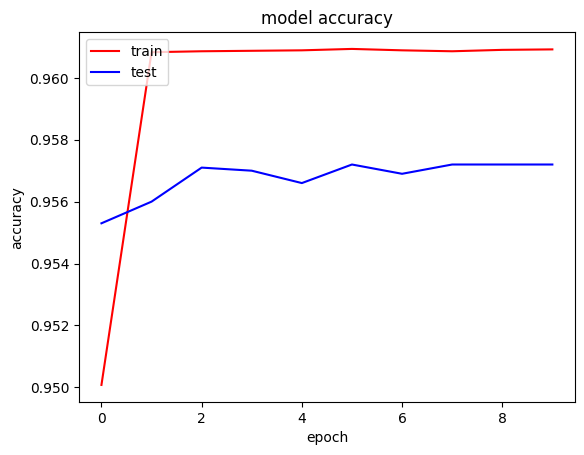

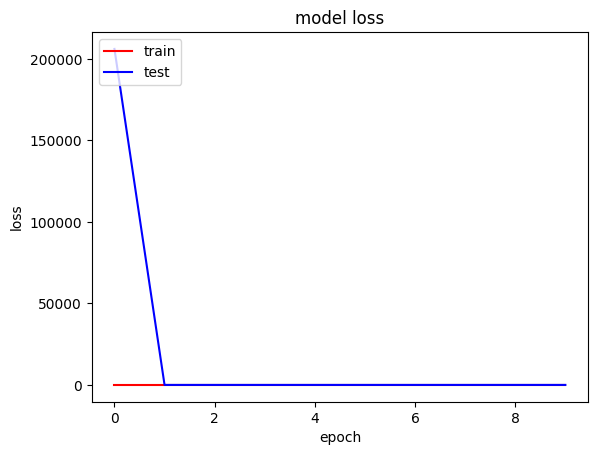

In [35]:
# Plot history

# Accuray 
plt.plot(history.history['accuracy'],'r')
plt.plot(history.history['val_accuracy'],'b')
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()
# Loss 
plt.plot(history.history['loss'],'r')
plt.plot(history.history['val_loss'],'b')

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

#### Uit bovenstaande accuracy en loss grafieken kunnen we opmaken dat reeds na een 3 tot 5-tal epochs een min of meer stabiel loss is op de test set.  Op de trainingsset blijft dit dalen, dus er is sprake van overfitting.  De model accuracy stijgt in hetzelfde aantal epochs naar een vrij constante en hoge waarde.  De verklaring hier is eenvoudig: door de sterke onbalans in de data haalt het model al deze hoge accuracy door eenvoudig te voorspellen dat alle klanten tevreden zijn.  Uiteraard kunnen we met een dergelijk model niks aanvangen... 

In [36]:
# Testen met test set
y_pred = model.predict(X_test)

y_pred = np.argmax(y_pred, axis=1)
print(y_pred)

print('\n')
print(classification_report(y_test_orig, y_pred))

cf = confusion_matrix(y_test_orig, y_pred)

print(cf)
print(accuracy_score(y_test_orig, y_pred) * 100) 

313/313 [==============================] - 0s 794us/step
[0 0 0 ... 0 0 0]


              precision    recall  f1-score   support

           0       0.96      1.00      0.98      9572
           1       0.00      0.00      0.00       428

    accuracy                           0.96     10000
   macro avg       0.48      0.50      0.49     10000
weighted avg       0.92      0.96      0.94     10000

[[9572    0]
 [ 428    0]]
95.72


/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


#### Resultaat van de classificatie met het "standaard" neuraal netwerk:

De recall bij de minderheidsklasse is dramatisch: 0,00.  Dit betekent dat, ondanks het goede resultaat van de accuracy, het model niet goed werkt.  Er moeten bijgevolg bijkomende stappen worden ondernomen om de prestaties op de minderheidsklasse te verbeteren.

### Neuraal netwerk met Class-weight balancing en Early stopping

In [37]:
# Met model checkpoint en early stopping with patience
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

# Class_weight
from sklearn.utils import class_weight

# Model checkpoint
mc = ModelCheckpoint('best_model.h5', monitor='val_accuracy', mode='max', verbose=1, save_best_only=True)

# Early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience = 20)

# Neuraal netwerk
model = Sequential()
dropoutrate = 0.3
batchsize = 128
inputdim = X_train.shape[1]  #336 input features
epochs=1000
model.add(Dense(40, input_dim=inputdim, kernel_initializer='uniform',activation='relu'))
model.add(Dropout(dropoutrate))
model.add(BatchNormalization())

model.add(Dense(20, kernel_initializer='uniform',activation='relu'))
model.add(Dropout(dropoutrate))
model.add(BatchNormalization())

model.add(Dense(2, activation='softmax'))

model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
              
class_weights = class_weight.compute_class_weight(class_weight='balanced',
                                                  classes=np.unique(y_train_orig),
                                                  y=y_train_orig)
print("Class weights:" ,class_weights)
class_weights= dict(enumerate(class_weights))
print (type(class_weights))

history = model.fit(X_train, 
                    y_train, 
                    validation_data=(X_test, y_test), 
                    validation_split=0.2,                      
                    epochs=epochs, 
                    verbose=1,
                    class_weight=class_weights,
                    callbacks=[es,mc],
                    batch_size=batchsize
                   )

Class weights: [ 0.52033417 12.79457364]
<class 'dict'>
Epoch 1/1000
516/516 [==============================] - ETA: 0s - loss: 0.6611 - accuracy: 0.6629
Epoch 1: val_accuracy improved from -inf to 0.81620, saving model to best_model.h5
516/516 [==============================] - 3s 4ms/step - loss: 0.6611 - accuracy: 0.6629 - val_loss: 0.4594 - val_accuracy: 0.8162
Epoch 2/1000
514/516 [============================>.] - ETA: 0s - loss: 0.5735 - accuracy: 0.7045
Epoch 2: val_accuracy improved from 0.81620 to 0.89750, saving model to best_model.h5
516/516 [==============================] - 2s 3ms/step - loss: 0.5737 - accuracy: 0.7047 - val_loss: 0.3826 - val_accuracy: 0.8975
Epoch 3/1000
511/516 [============================>.] - ETA: 0s - loss: 0.5600 - accuracy: 0.7276
Epoch 3: val_accuracy did not improve from 0.89750
516/516 [==============================] - 2s 3ms/step - loss: 0.5601 - accuracy: 0.7274 - val_loss: 0.4716 - val_accuracy: 0.8459
Epoch 4/1000
508/516 [===============

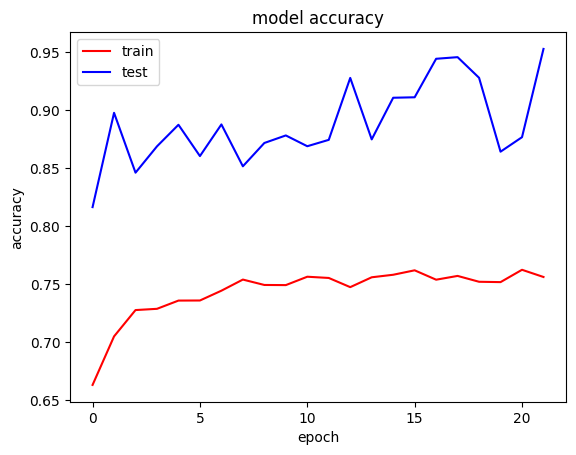

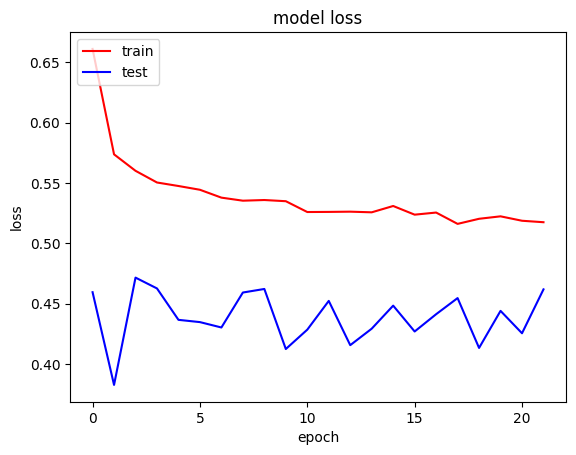

In [38]:
# Plot history

# Accuray 
plt.plot(history.history['accuracy'],'r')
plt.plot(history.history['val_accuracy'],'b')
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()
# Loss 
plt.plot(history.history['loss'],'r')
plt.plot(history.history['val_loss'],'b')

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

#### Op de accuracy en loss plot hierboven zien we dat de accuracy op de test set hoger is dan op de train set.  Dit is wellicht omdat tijdens de training gebruik wordt gemaakt van dropout, waardoor het netwerk niet op volle sterkte werkt, terwijl dit met de test set wel zo is.  De loss is grillig; er zit een variatie van zo'n 10% op voor de test set.  De loss op de test set daalt na enkele epochs niet echt verder in functie van de tijd, terwijl dit voor de trainingsset wel zo is.  Dit betekent ook hier dat het model gaat overfitten.

In [39]:
# Inladen van het beste model
saved_model = load_model('best_model.h5')
# Evalueren van het beste model
_, train_acc = saved_model.evaluate(X_train, y_train, verbose=0)
_, test_acc = saved_model.evaluate(X_test, y_test, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))

Train: 0.957, Test: 0.953


In [40]:
# Testen met test set
y_pred = model.predict(X_test)

y_pred = np.argmax(y_pred, axis=1)
print('\n')
print(classification_report(y_test_orig, y_pred))

cf = confusion_matrix(y_test_orig, y_pred)

print(cf)
print(accuracy_score(y_test_orig, y_pred) * 100) 

313/313 [==============================] - 0s 811us/step


              precision    recall  f1-score   support

           0       0.96      0.99      0.98      9572
           1       0.24      0.05      0.08       428

    accuracy                           0.95     10000
   macro avg       0.60      0.52      0.53     10000
weighted avg       0.93      0.95      0.94     10000

[[9505   67]
 [ 407   21]]
95.26


#### Via class-weight balancing komen we op een accuracy van ongeveer 80 % op de test set (op test set is dit hoger omwille van dropout) met een recall van 81% op de meerderheidsklasse en 68% op de minderheidsklasse.

### Data augmentation via SMOTE

In [41]:
# Features en targets splitsen
features = list(dataset4smote.columns[:dataset4smote.columns.size-1])
X = dataset4smote[features].values
y = dataset4smote['TARGET'].values

In [42]:
# Converteer naar een numpy array
# X_train = X_train.values
# X_test = X_test.values

# Niet gebalanceerde data: "balanceren" via SMOTE
from imblearn.over_sampling import BorderlineSMOTE
X_resampled, y_resampled = BorderlineSMOTE().fit_resample(X_train, y_train)

# Splits op in training set en test set
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size = 10000, random_state = 42)


# One-hot encoding van de targets
y_resampled_orig = y_resampled
y_resampled = to_categorical(y_resampled)

y_test_orig = y_test
y_test = to_categorical(y_test)

# normaliseren van de features
# via robustscaler: This Scaler removes the median and scales the data according to the quantile range 
from sklearn.preprocessing import RobustScaler
Rscaler = RobustScaler()
Rscaler.fit(X_train)

X_train = Rscaler.transform(X_resampled)
X_test = Rscaler.transform(X_test)

In [43]:
# Is de dataset nu gebalanceerd?
label_count = np.bincount(y_resampled_orig)

print('count klasse 0: ',label_count[0])
print('count klasse 1: ',label_count[1])

print('ratio: ',label_count[0]/label_count[1])

ValueError: object too deep for desired array

### Na toepassing van SMOTE is de dataset nu uiteraard gebalanceerd.

In [ ]:
# Initialiseren van het neuraal netwerk met SMOTE

## parameters van het NN
model = Sequential()
dropoutrate = 0.4
batchsize = 16
inputdim = X_train.shape[1]  #336 input features

# Early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience = 10)

model.add(Dense(80, input_dim=inputdim, kernel_initializer='uniform',activation='relu'))

model.add(Dense(160, kernel_initializer='uniform',activation='relu'))
model.add(Dropout(dropoutrate))
model.add(BatchNormalization())

model.add(Dense(80, kernel_initializer='uniform',activation='relu'))
model.add(Dropout(dropoutrate))
model.add(BatchNormalization())

model.add(Dense(20, kernel_initializer='uniform',activation='relu'))
model.add(Dropout(dropoutrate))
model.add(BatchNormalization())

model.add(Dense(2, activation='softmax'))

# model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
# Trainen van het model
history = model.fit(X_resampled, 
                    y_resampled, 
                    epochs=100,
                    validation_split=0.3, 
                    batch_size=batchsize,
                    callbacks=[es],
                    verbose=1)

In [ ]:
# Testen met test set
y_pred = model.predict(X_test)
y_pred = np.argmax(y_pred, axis=1)
print('\n')
print(classification_report(y_test_orig, y_pred))

cf = confusion_matrix(y_test_orig, y_pred)

print(cf)
print(accuracy_score(y_test_orig, y_pred) * 100) 

### Conclusie:

Het beste resultaat werd bekomen met behulp van class-weight balancing; daarmee komen we op een accuracy van 80 % op de test set (op test set is dit hoger omwille van dropout) met een recall van 81% op de meerderheidsklasse en 68% op de minderheidsklasse.

Met SMOTE bekom ik geen goed resultaat.


## Zalando 

Fashion-MNIST is een dataset van Zalando bestaande uit afbeeldingen van kledij. De training set ('fashion-mnist_train.csv') bestaat uit 60000 afbeeldingen, de test set ('fashion-mnist_test.csv') uit 10000 afbeeldingen.
Elke grijsafbeelding is 28x28 pixels groot en is toegewezen aan één van de 10 klasses: 

0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'.

Train een neuraal netwerk dat een zo hoog mogelijke accuracy score behaalt op de test set.
Eén optie is om als features de ruwe pixeldata (784 pixels) te gebruiken. Een andere benadering is om via Principle Component Analysis (PCA) de featureset te reduceren en daarmee als het ware feature extraction toe te passen.
Onderzoek welke afbeeldingen niet correct werden geclassificeerd en visualiseer ze.

Tijdens de volgende sessie zullen we op dezelfde dataset convolutional neural networks toepassen. Deze neurale netwerk architectuur leent zich uitstekend voor image classification.

Vergelijk jouw eigen accuracy score met deze opgelijst op https://github.com/zalandoresearch/fashion-mnist.


In [6]:
df_train = pd.read_csv('../DATA/fashion-mnist_train.csv')
df_test = pd.read_csv('../DATA/fashion-mnist_test.csv')
df_train.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
# Uitwerking Zalando oefening
df_train.shape

(60000, 785)

In [8]:
#Opsplitsen in features en targets
# values uit kolom label halen
train_labels = df_train.label.values
test_labels = df_test.label.values

y_test_orig = test_labels

y_train = to_categorical(train_labels)
y_test = to_categorical(test_labels)

X_train = df_train.drop('label',axis=1).values
X_test  = df_test.drop('label',axis=1).values

print(y_train.shape)
print(y_test.shape)
print(X_train.shape)
print(X_test.shape)

(60000, 10)
(10000, 10)
(60000, 784)
(10000, 784)


# Uitwerking zonder Principal Components Analysis

In [9]:
# scalen
X_train_scaled = X_train / 255
X_test_scaled = X_test / 255

In [10]:
# initialiseren van het neuraal netwerk

activation = 'relu'
dropout_rate = 0.4
kernel_initializer ='uniform'
optimizer = 'adam'
lr = 0.01
batchsize = 128

# Model checkpoint
mc = ModelCheckpoint('best_model.h5', monitor='val_accuracy', mode='max', verbose=1, save_best_only=True)
# val_accuracy ipv val_acc!

# Early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience = 20)

# Model
model = Sequential()
model.add(Dense(128, input_dim=X_train_scaled.shape[1], kernel_initializer=kernel_initializer,activation=activation))
model.add(Dropout(dropout_rate))
model.add(Dense(128, kernel_initializer=kernel_initializer,activation=activation))
model.add(Dropout(dropout_rate))

model.add(Dense(10,activation = 'softmax'))

model.compile(loss='categorical_crossentropy', optimizer=optimizer,metrics=['accuracy']) 

In [11]:
history = model.fit(X_train_scaled, y_train, validation_split=0.3, validation_data=(X_test_scaled, y_test), epochs=500, batch_size=batchsize,verbose=1,callbacks=[es,mc])

Epoch 1/500
458/469 [============================>.] - ETA: 0s - loss: 0.7164 - accuracy: 0.7443
Epoch 1: val_accuracy improved from -inf to 0.83780, saving model to best_model.h5
469/469 [==============================] - 2s 3ms/step - loss: 0.7123 - accuracy: 0.7459 - val_loss: 0.4463 - val_accuracy: 0.8378
Epoch 2/500
462/469 [============================>.] - ETA: 0s - loss: 0.4862 - accuracy: 0.8291
Epoch 2: val_accuracy improved from 0.83780 to 0.86200, saving model to best_model.h5
469/469 [==============================] - 1s 2ms/step - loss: 0.4868 - accuracy: 0.8291 - val_loss: 0.3908 - val_accuracy: 0.8620
Epoch 3/500
463/469 [============================>.] - ETA: 0s - loss: 0.4422 - accuracy: 0.8409
Epoch 3: val_accuracy improved from 0.86200 to 0.86220, saving model to best_model.h5
469/469 [==============================] - 1s 2ms/step - loss: 0.4422 - accuracy: 0.8408 - val_loss: 0.3727 - val_accuracy: 0.8622
Epoch 4/500
468/469 [============================>.] - ETA: 0

469/469 [==============================] - 1s 2ms/step - loss: 0.2995 - accuracy: 0.8887 - val_loss: 0.3018 - val_accuracy: 0.8900
Epoch 29/500
454/469 [============================>.] - ETA: 0s - loss: 0.2980 - accuracy: 0.8897
Epoch 29: val_accuracy did not improve from 0.89230
469/469 [==============================] - 1s 2ms/step - loss: 0.2978 - accuracy: 0.8899 - val_loss: 0.3104 - val_accuracy: 0.8877
Epoch 30/500
456/469 [============================>.] - ETA: 0s - loss: 0.2982 - accuracy: 0.8903
Epoch 30: val_accuracy did not improve from 0.89230
469/469 [==============================] - 1s 2ms/step - loss: 0.2979 - accuracy: 0.8906 - val_loss: 0.3021 - val_accuracy: 0.8901
Epoch 31/500
454/469 [============================>.] - ETA: 0s - loss: 0.2947 - accuracy: 0.8910
Epoch 31: val_accuracy improved from 0.89230 to 0.89260, saving model to best_model.h5
469/469 [==============================] - 1s 2ms/step - loss: 0.2951 - accuracy: 0.8906 - val_loss: 0.2994 - val_accuracy

466/469 [============================>.] - ETA: 0s - loss: 0.2663 - accuracy: 0.9022
Epoch 57: val_accuracy did not improve from 0.89860
469/469 [==============================] - 1s 2ms/step - loss: 0.2665 - accuracy: 0.9021 - val_loss: 0.2983 - val_accuracy: 0.8953
Epoch 58/500
458/469 [============================>.] - ETA: 0s - loss: 0.2631 - accuracy: 0.9018
Epoch 58: val_accuracy did not improve from 0.89860
469/469 [==============================] - 1s 2ms/step - loss: 0.2631 - accuracy: 0.9016 - val_loss: 0.2974 - val_accuracy: 0.8942
Epoch 59/500
468/469 [============================>.] - ETA: 0s - loss: 0.2603 - accuracy: 0.9019
Epoch 59: val_accuracy did not improve from 0.89860
469/469 [==============================] - 1s 2ms/step - loss: 0.2605 - accuracy: 0.9019 - val_loss: 0.3006 - val_accuracy: 0.8942
Epoch 60/500
444/469 [===========================>..] - ETA: 0s - loss: 0.2587 - accuracy: 0.9027
Epoch 60: val_accuracy did not improve from 0.89860
469/469 [===========

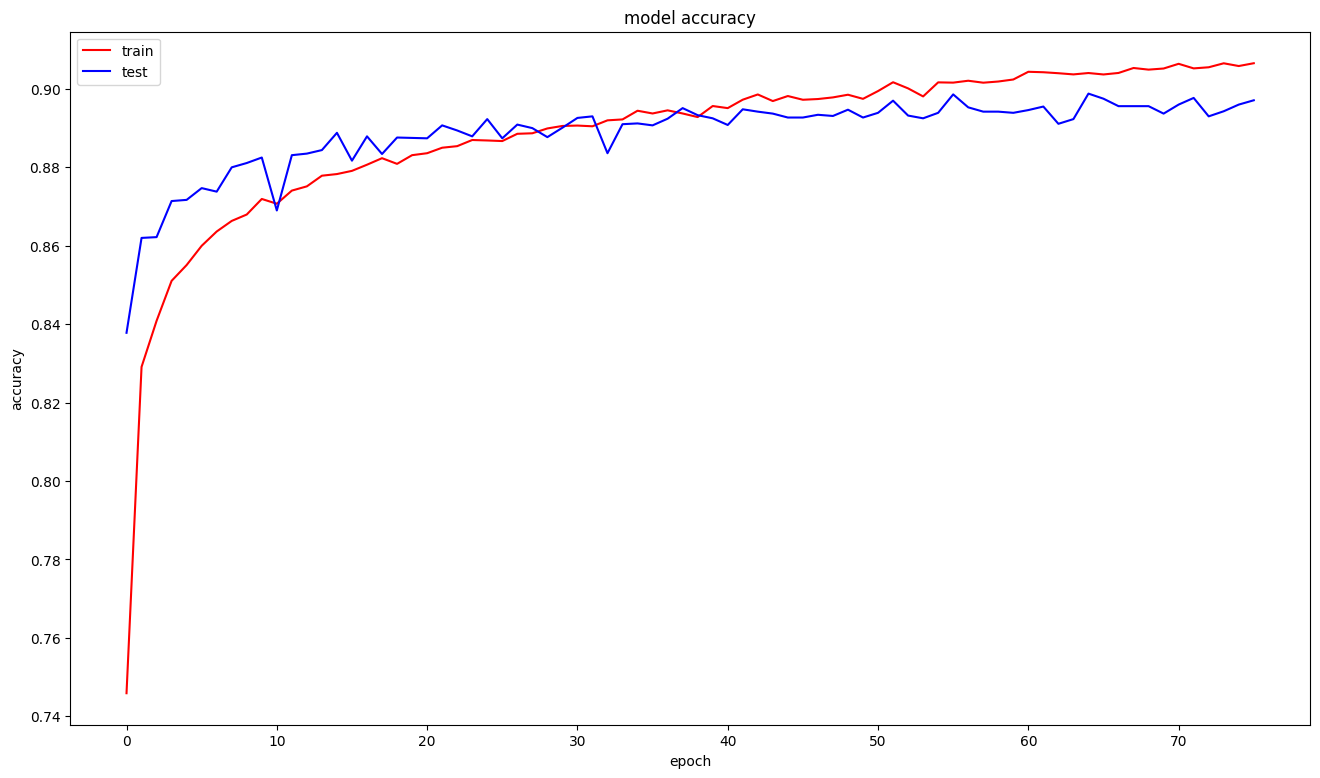

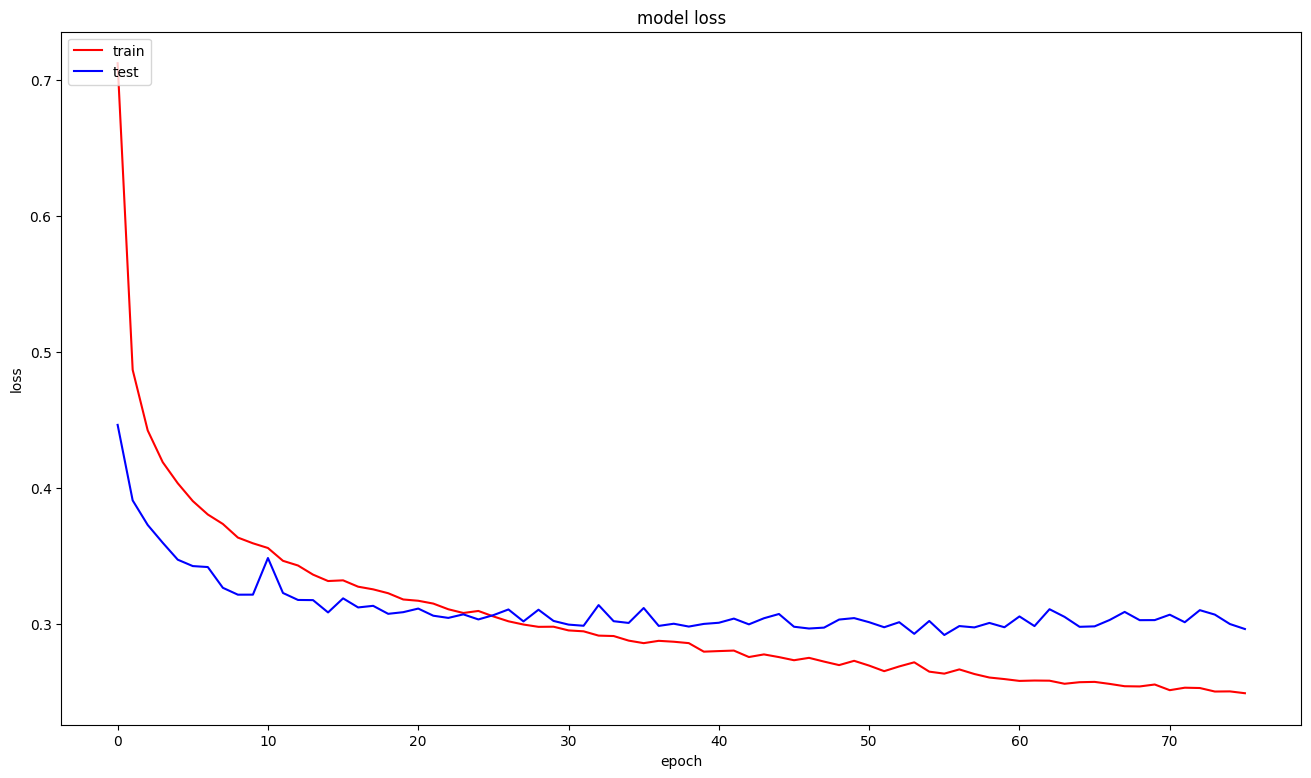

In [12]:
# Plot history

# Accuray 
fig = plt.figure(figsize=(16,9))
plt.plot(history.history['accuracy'],'r')
plt.plot(history.history['val_accuracy'],'b')
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()
# Loss 
fig = plt.figure(figsize=(16,9))
plt.plot(history.history['loss'],'r')
plt.plot(history.history['val_loss'],'b')

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [13]:
# Inladen van het beste model
saved_model = load_model('best_model.h5')
# Evalueren van het beste model
_, train_acc = saved_model.evaluate(X_train, y_train, verbose=0)
_, test_acc = saved_model.evaluate(X_test, y_test, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))

Train: 0.902, Test: 0.872


# Uitwerking met Principal Components Analysis

In [14]:
# Principle Component Analysis
number_of_components = 50
from sklearn.decomposition import PCA

# Train het PCA algoritme op de training data
pca_model = PCA(n_components=number_of_components, svd_solver='full')
pca_model.fit(X_train)

# Reduceer het aantal dimensies van zowel de trainig set als de test set
X_train_pca = pca_model.transform(X_train)
X_test_pca = pca_model.transform(X_test)

# Normaliseer de PCA componenten
X_train_pca = X_train_pca / X_train_pca.max()
X_test_pca = X_test_pca / X_test_pca.max()

In [15]:
# initialiseren van het neuraal netwerk

activation = 'relu'
dropout_rate = 0.3
kernel_initializer ='uniform'
optimizer = 'adam'
lr = 0.01
batchsize = 32

# Model checkpoint
mc = ModelCheckpoint('best_model.h5', monitor='val_accuracy', mode='max', verbose=1, save_best_only=True)
# val_accuracy ipv val_acc!

# Early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience = 20)

model = Sequential()
model.add(Dense(64, input_dim=number_of_components, kernel_initializer=kernel_initializer,activation=activation))
model.add(Dropout(dropout_rate))
model.add(Dense(32, kernel_initializer=kernel_initializer,activation=activation))
model.add(Dropout(dropout_rate))
# model.add(Dense(200, kernel_initializer=kernel_initializer,activation=activation))
# model.add(Dropout(dropout_rate))
# model.add(Dense(200, kernel_initializer=kernel_initializer,activation=activation))
# model.add(Dropout(dropout_rate))
model.add(Dense(10,activation = 'softmax'))


model.compile(loss='categorical_crossentropy', optimizer=optimizer,metrics=['accuracy']) 

In [16]:
history = model.fit(X_train_pca, y_train, epochs=500,validation_split=0.30, callbacks=[es,mc], batch_size=batchsize,verbose=1)

Epoch 1/500
1261/1313 [===========================>..] - ETA: 0s - loss: 0.9659 - accuracy: 0.6637
Epoch 1: val_accuracy improved from -inf to 0.79439, saving model to best_model.h5
1313/1313 [==============================] - 2s 1ms/step - loss: 0.9545 - accuracy: 0.6674 - val_loss: 0.5683 - val_accuracy: 0.7944
Epoch 2/500
1289/1313 [============================>.] - ETA: 0s - loss: 0.6326 - accuracy: 0.7761
Epoch 2: val_accuracy improved from 0.79439 to 0.81483, saving model to best_model.h5
1313/1313 [==============================] - 1s 1ms/step - loss: 0.6322 - accuracy: 0.7763 - val_loss: 0.5133 - val_accuracy: 0.8148
Epoch 3/500
1291/1313 [============================>.] - ETA: 0s - loss: 0.5792 - accuracy: 0.7958
Epoch 3: val_accuracy improved from 0.81483 to 0.82450, saving model to best_model.h5
1313/1313 [==============================] - 1s 1ms/step - loss: 0.5787 - accuracy: 0.7962 - val_loss: 0.4802 - val_accuracy: 0.8245
Epoch 4/500
1292/1313 [==========================

1313/1313 [==============================] - 1s 1ms/step - loss: 0.4154 - accuracy: 0.8527 - val_loss: 0.3721 - val_accuracy: 0.8687
Epoch 28/500
1274/1313 [============================>.] - ETA: 0s - loss: 0.4098 - accuracy: 0.8530
Epoch 28: val_accuracy did not improve from 0.86872
1313/1313 [==============================] - 1s 1ms/step - loss: 0.4103 - accuracy: 0.8533 - val_loss: 0.3749 - val_accuracy: 0.8660
Epoch 29/500
1302/1313 [============================>.] - ETA: 0s - loss: 0.4096 - accuracy: 0.8564
Epoch 29: val_accuracy did not improve from 0.86872
1313/1313 [==============================] - 1s 1ms/step - loss: 0.4102 - accuracy: 0.8564 - val_loss: 0.3715 - val_accuracy: 0.8685
Epoch 30/500
1297/1313 [============================>.] - ETA: 0s - loss: 0.4133 - accuracy: 0.8532
Epoch 30: val_accuracy did not improve from 0.86872
1313/1313 [==============================] - 1s 1ms/step - loss: 0.4137 - accuracy: 0.8531 - val_loss: 0.3722 - val_accuracy: 0.8669
Epoch 31/500

Epoch 56/500
1301/1313 [============================>.] - ETA: 0s - loss: 0.3922 - accuracy: 0.8603
Epoch 56: val_accuracy did not improve from 0.87339
1313/1313 [==============================] - 1s 1ms/step - loss: 0.3919 - accuracy: 0.8605 - val_loss: 0.3600 - val_accuracy: 0.8726
Epoch 57/500
1297/1313 [============================>.] - ETA: 0s - loss: 0.3922 - accuracy: 0.8605
Epoch 57: val_accuracy improved from 0.87339 to 0.87483, saving model to best_model.h5
1313/1313 [==============================] - 1s 1ms/step - loss: 0.3922 - accuracy: 0.8606 - val_loss: 0.3629 - val_accuracy: 0.8748
Epoch 58/500
1312/1313 [============================>.] - ETA: 0s - loss: 0.3908 - accuracy: 0.8595
Epoch 58: val_accuracy did not improve from 0.87483
1313/1313 [==============================] - 1s 1ms/step - loss: 0.3907 - accuracy: 0.8595 - val_loss: 0.3616 - val_accuracy: 0.8726
Epoch 59/500
1263/1313 [===========================>..] - ETA: 0s - loss: 0.3915 - accuracy: 0.8603
Epoch 59: 

Epoch 85/500
1277/1313 [============================>.] - ETA: 0s - loss: 0.3802 - accuracy: 0.8636
Epoch 85: val_accuracy did not improve from 0.87483
1313/1313 [==============================] - 2s 1ms/step - loss: 0.3795 - accuracy: 0.8641 - val_loss: 0.3596 - val_accuracy: 0.8736
Epoch 86/500
1265/1313 [===========================>..] - ETA: 0s - loss: 0.3821 - accuracy: 0.8616
Epoch 86: val_accuracy did not improve from 0.87483
1313/1313 [==============================] - 2s 1ms/step - loss: 0.3819 - accuracy: 0.8619 - val_loss: 0.3583 - val_accuracy: 0.8744
Epoch 87/500
1256/1313 [===========================>..] - ETA: 0s - loss: 0.3813 - accuracy: 0.8618
Epoch 87: val_accuracy did not improve from 0.87483
1313/1313 [==============================] - 1s 1ms/step - loss: 0.3809 - accuracy: 0.8621 - val_loss: 0.3605 - val_accuracy: 0.8726
Epoch 88/500
1287/1313 [============================>.] - ETA: 0s - loss: 0.3810 - accuracy: 0.8628
Epoch 88: val_accuracy did not improve from 0

1257/1313 [===========================>..] - ETA: 0s - loss: 0.3804 - accuracy: 0.8624
Epoch 113: val_accuracy did not improve from 0.87583
1313/1313 [==============================] - 1s 1ms/step - loss: 0.3791 - accuracy: 0.8630 - val_loss: 0.3561 - val_accuracy: 0.8747
Epoch 114/500
1295/1313 [============================>.] - ETA: 0s - loss: 0.3731 - accuracy: 0.8658
Epoch 114: val_accuracy did not improve from 0.87583
1313/1313 [==============================] - 1s 1ms/step - loss: 0.3740 - accuracy: 0.8656 - val_loss: 0.3566 - val_accuracy: 0.8743
Epoch 115/500
1298/1313 [============================>.] - ETA: 0s - loss: 0.3749 - accuracy: 0.8652
Epoch 115: val_accuracy did not improve from 0.87583
1313/1313 [==============================] - 1s 1ms/step - loss: 0.3746 - accuracy: 0.8652 - val_loss: 0.3548 - val_accuracy: 0.8733
Epoch 116/500
1282/1313 [============================>.] - ETA: 0s - loss: 0.3772 - accuracy: 0.8633
Epoch 116: val_accuracy did not improve from 0.87583

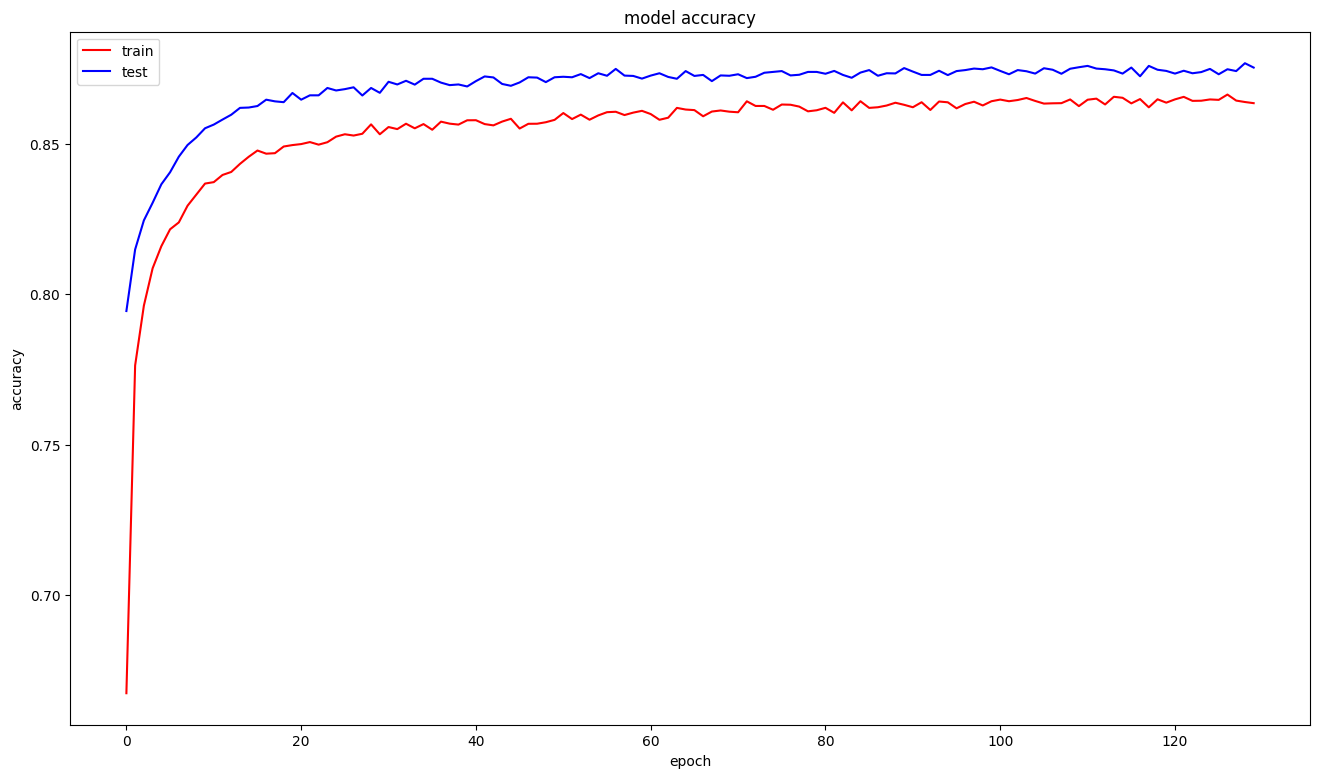

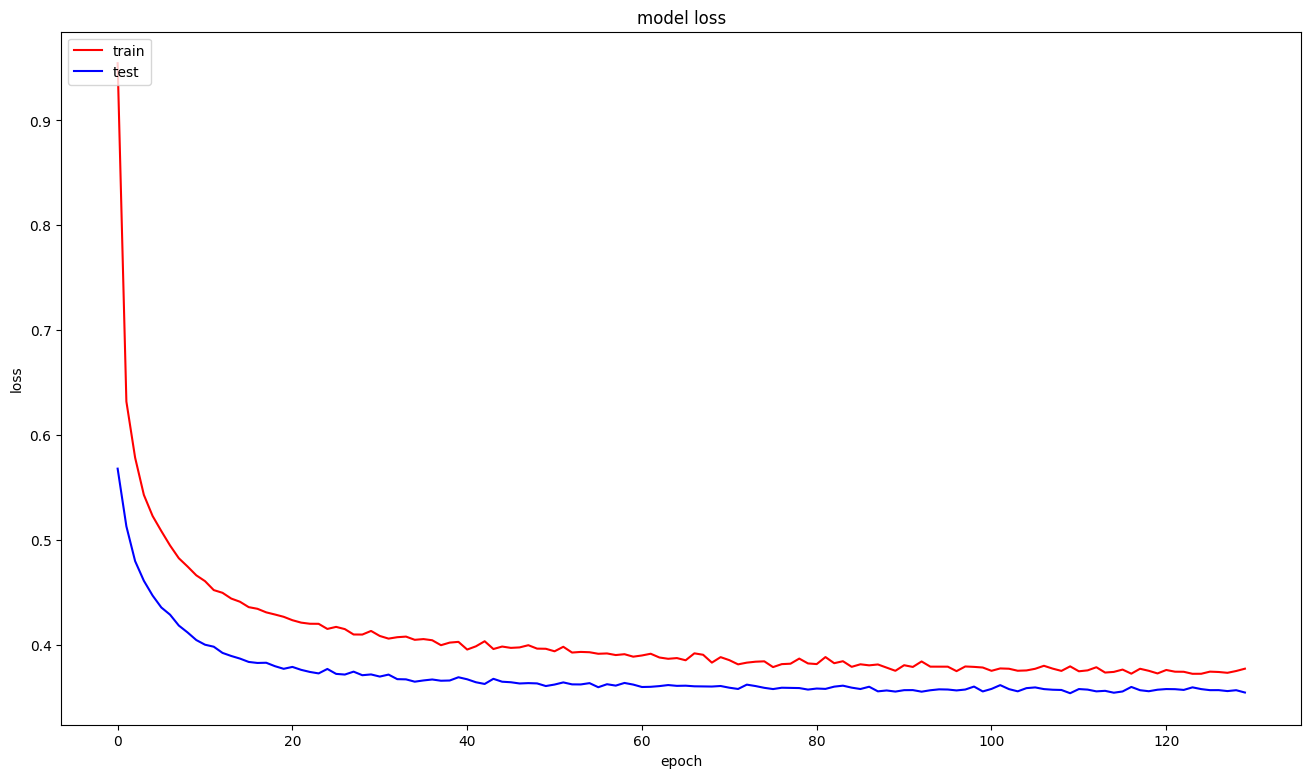

In [17]:
# Plot history

# Accuray 
fig = plt.figure(figsize=(16,9))
plt.plot(history.history['accuracy'],'r')
plt.plot(history.history['val_accuracy'],'b')
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()
# Loss 
fig = plt.figure(figsize=(16,9))
plt.plot(history.history['loss'],'r')
plt.plot(history.history['val_loss'],'b')

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [18]:
# Inladen van het beste model
saved_model = load_model('best_model.h5')
# Evalueren van het beste model
_, train_acc = saved_model.evaluate(X_train_pca, y_train, verbose=0)
_, test_acc = saved_model.evaluate(X_test_pca, y_test, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))

Train: 0.891, Test: 0.875


In [19]:
y_predicted = model.predict(X_test_pca,batch_size=1, verbose=1)

10000/10000 [==============================] - 6s 548us/step


In [20]:
# omzetten y_predicted
y_predicted = np.argmax(y_predicted, axis=1)

In [21]:
# verkeerd geklassificeerde kledingstukken:

verkeerdgeklasseerd = []
correcteKlasse = []
for i in range (len(y_predicted)):
    if y_test_orig[i] != y_predicted[i]:
        verkeerdgeklasseerd.append(i+1)
        correcteKlasse.append(y_test_orig[i])
        
print(len(verkeerdgeklasseerd))

1250


<ipython-input-22-f0388c2c391d>:15: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(rijen, kolommen,nummer+1)


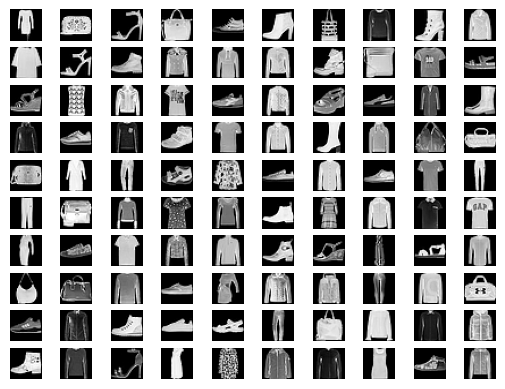

In [22]:
# Visualisatie verkeerd geklasseerde kledingstukken

# aantal te tonen stukken 
aantal = 100
kolommen = 10
rijen = 10

plt.axis('off') 
i = 0
j = 0

nummer = 0
for i in range (rijen):
    for j in range (kolommen):
        plt.subplot(rijen, kolommen,nummer+1)
        plt.imshow(X_test[verkeerdgeklasseerd[nummer]].reshape(28,28),cmap='gray') 
        plt.axis('off')
        j +=1
        nummer +=1
    i +=1

#### Conclusie: met behulp van Principal Components Analysis worden betere resultaten bekomen: een accuracy op de training set van 89,2 en op de test set van 87,4 waar zonder PCA "slechts" 81,7 op de training set en 80,5 op de test set werd gehaald.  Dit komt evenwel met een prijs: met PCA analyse hebben we 238 epochs nodig om tot het beste resultaat te komen, terwijl we zonder PCA minder dan de helft nodig hadden: 110 epochs.  Het betekent wel dat er met PCA langer verbeteringen zijn in het model.  Met PCA hadden we 580 seconden nodig (2,44 seconden/epoch), zonder PCA 75 seconden (0,68 seconden/epoch).

#### Na ongeveer 50 epochs begint het model zonder PCA te overfitten: het leert de trainingsset vanbuiten, terwijl op de test set de resultaten beginnen achteruit tegaan.  Met behulp van PCA is er geen overfitting.  Het model zonder PCA kan eenvoudiger worden gemaakt (minder neuronen / laag of minder lagen) of er kan sterkere regularisatie worden toegepast, maar ik heb de modellen identiek gehouden om te kunnen vergelijken. 

#### In vergelijking met gelijkaardige modellen presteert mijn model enkele procenten lager.

#### In de getoonde fout geklasseerde afbeeldingen is het duidelijk dat het niet evident is om een kledingsstuk in de juiste categorie te classificeren: de omtrek van een kledingsstuk geeft niet altijd goed aan of het nu een pullover of bijvoobeeld een coat betreft...